In [24]:

# ============================================================
# ASD NEUROPIXELS REANALYSIS — ENVIRONMENT SETUP
# Run this cell once after every Colab runtime restart.
# ============================================================

# 1. Install required packages
%pip -q install one-api ibllib iblatlas numpy pandas scipy matplotlib seaborn scikit-learn statsmodels h5py pyarrow openpyxl tqdm psutil

# 2. Standard libraries
import os
import gc
import sys
import json
import time
import warnings
from pathlib import Path
from collections import defaultdict

# 3. Scientific computing
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Statistics and utilities
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm
import psutil

# 5. IBL / Neuropixels
from one.api import ONE
from brainbox.io.one import SpikeSortingLoader
from iblatlas.regions import BrainRegions

# 6. Google Drive
from google.colab import drive

drive.mount("/content/drive")

# 7. Project directories
ROOT = Path(
    "/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis"
)

DOCS = ROOT / "00_documentation"
NOTEBOOKS = ROOT / "01_notebooks"
META = ROOT / "02_session_metadata"
OUTPUT = ROOT / "03_processed_data"
RESULTS = ROOT / "04_results"
FIGURES = ROOT / "05_figures"

for folder in [DOCS, NOTEBOOKS, META, OUTPUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# 8. IBL connection
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

# 9. Anatomical reference
atlas = pd.read_csv(META / "allen_region_dictionary.csv")
inventory = pd.read_csv(META / "mouse_probe_inventory.csv")

region_map = dict(
    zip(atlas["allen_acronym"], atlas["analysis_region"])
)

valid_regions = set(atlas["allen_acronym"])
brain_regions = BrainRegions()

# 10. Display and plotting defaults
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="ticks", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# 11. Environment summary
print("=" * 55)
print("ASD NEUROPIXELS REANALYSIS — READY")
print("=" * 55)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("IBL connection:", one.alyx.base_url)
print("Project:", ROOT)
print("Animals:", inventory.subject.nunique())
print("Insertions:", len(inventory))
print("Anatomical labels:", len(atlas))
print("RAM available:",
      round(psutil.virtual_memory().available / 1024**3, 2),
      "GB")
print("Disk available:",
      round(psutil.disk_usage("/content").free / 1024**3, 2),
      "GB")
print("=" * 55)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ASD NEUROPIXELS REANALYSIS — READY
Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
IBL connection: https://openalyx.internationalbrainlab.org
Project: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis
Animals: 62
Insertions: 364
Anatomical labels: 24
RAM available: 9.84 GB
Disk available: 89.35 GB


In [38]:

# ============================================================
# WT BURST RECALCULATION — COMPLETE PIPELINE
# ============================================================
#
# Method: modified logISI-core
#
# Corrections:
# - Reference-based logISI histogram and peak detection
# - Void parameter >= 0.7
# - Adaptive threshold below 100 ms when detected
# - Otherwise, 100 ms burst-core threshold
# - No extension of bursts beyond the 100 ms core cutoff
# - Minimum 3 spikes per burst
#
# Preserved:
# - Firing rate
# - Mean ISI
# - CV ISI and CV2
# - Anatomical labels and metadata
# - Spike counts and recording duration
#
# Existing CSV files are overwritten in place.
# No new permanent data files are created.
#
# The processing log tracks completed recalculations.
# ============================================================


# ------------------------------------------------------------
# 1. PROJECT PATHS AND EXISTING WT RECORDS
# ------------------------------------------------------------

WT_DIR = ROOT / "03_processed_data" / "WT"
LOG_PATH = WT_DIR / "processing_log.csv"

BURST_VERSION = "logisi_core_v1"

log = pd.read_csv(LOG_PATH)

assert len(log) == 99, (
    f"Expected 99 insertions, found {len(log)}"
)

assert log["pid"].nunique() == 99

log["pid"] = log["pid"].astype(str)

if "burst_version" not in log.columns:
    log["burst_version"] = ""

log["burst_version"] = log["burst_version"].fillna("")

burst_columns = [
    "logisi_threshold_ms",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]

preserved_columns = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "n_spikes",
    "duration_s",
    "original_region",
    "subject",
    "cluster_id"
]

missing_files = [
    pid for pid in log["pid"]
    if not (WT_DIR / f"{pid}.csv").exists()
]

if missing_files:
    raise RuntimeError(
        f"Missing {len(missing_files)} insertion CSV files"
    )

print("=" * 60)
print("WT BURST RECALCULATION")
print("=" * 60)
print("Insertions:", len(log))
print("Method:", BURST_VERSION)
print("Existing files:", len(log) - len(missing_files))


# ------------------------------------------------------------
# 2. ATOMIC CSV REPLACEMENT
# ------------------------------------------------------------

def save_csv_safely(data, path, **kwargs):
    """
    Write to a temporary file, then replace the original.
    The temporary file is not retained after success.
    """
    temp = path.with_name(path.name + ".tmp")

    try:
        data.to_csv(temp, index=False, **kwargs)
        os.replace(temp, path)
    finally:
        if temp.exists():
            temp.unlink()


# ------------------------------------------------------------
# 3. LOGISI THRESHOLD ESTIMATION
# ------------------------------------------------------------

def estimate_logisi_core_threshold(times, cutoff_ms=100.0):
    """
    Reference-inspired logISI threshold estimation.

    Returns:
        threshold_ms
        detection_mode

    This is the project's modified logISI-core method,
    not an exact reproduction of the full Pasquale method.
    """

    isi_ms = np.diff(times) * 1000
    isi_ms = isi_ms[
        np.isfinite(isi_ms) & (isi_ms > 0)
    ]

    if len(isi_ms) < 4:
        return np.nan, "insufficient_isi"

    included = isi_ms[isi_ms >= 1]

    if len(included) < 4:
        return np.nan, "insufficient_isi"

    max_power = max(
        1,
        int(np.ceil(np.log10(isi_ms.max())))
    )

    n_edges = max(11, 10 * max_power)

    edges = np.logspace(
        0,
        max_power,
        n_edges
    )

    counts, edges = np.histogram(
        included,
        bins=edges
    )

    if counts.sum() == 0:
        return np.nan, "empty_histogram"

    density = counts.astype(float) / counts.sum()

    smooth = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        it=3,
        return_sorted=False
    )

    # Reference-inspired local peak detection.
    peaks = []

    for j in range(2, len(smooth) - 2):

        local = smooth[j - 2:j + 3]

        if (
            smooth[j] > local[1]
            and smooth[j] > local[3]
            and smooth[j] >= local[0]
            and smooth[j] >= local[4]
        ):
            if not peaks or j - peaks[-1] >= 2:
                peaks.append(j)

    peaks = np.asarray(peaks, dtype=int)

    if len(peaks) == 0:
        return np.nan, "no_intraburst_peak"

    peak_ms = edges[peaks]

    intraburst = peaks[
        peak_ms < cutoff_ms
    ]

    if len(intraburst) == 0:
        return np.nan, "no_intraburst_peak"

    first = intraburst[
        np.argmax(smooth[intraburst])
    ]

    later = peaks[peaks > first]

    if len(later) == 0:
        return cutoff_ms, "core_100ms"

    for second in later:

        valley = first + np.argmin(
            smooth[first:second + 1]
        )

        denominator = np.sqrt(
            max(smooth[first], 0) *
            max(smooth[second], 0)
        )

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void >= 0.7:

            threshold_ms = float(edges[valley])

            if threshold_ms < cutoff_ms:
                return threshold_ms, "adaptive"

            return cutoff_ms, "core_100ms"

    return cutoff_ms, "core_100ms"


# ------------------------------------------------------------
# 4. BURST DETECTION AND METRICS
# ------------------------------------------------------------

def calculate_logisi_core_metrics(times, duration):
    """
    Recalculate burst-related electrophysiological metrics
    without modifying conventional spike train metrics.
    """

    times = np.sort(np.asarray(times, dtype=float))

    threshold_ms, mode = estimate_logisi_core_threshold(
        times
    )

    result = {
        "logisi_threshold_ms": threshold_ms,
        "burst_rate_min": 0.0,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan,
    }

    if not np.isfinite(threshold_ms):
        return result

    threshold_s = threshold_ms / 1000

    isi = np.diff(times)

    short = (
        (isi > 0) &
        (isi <= threshold_s)
    )

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )

    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    valid = (
        ends - starts + 1 >= 3
    )

    starts = starts[valid]
    ends = ends[valid]

    n_bursts = len(starts)

    result["burst_rate_min"] = (
        n_bursts * 60 / duration
    )

    if n_bursts == 0:
        return result

    counts = ends - starts + 1

    durations = (
        times[ends] - times[starts]
    )

    result["burst_fraction_pct"] = (
        100 * counts.sum() / len(times)
    )

    result["burst_duration_ms"] = (
        durations.mean() * 1000
    )

    result["spikes_per_burst"] = (
        counts.mean()
    )

    positive_duration = durations > 0

    if np.any(positive_duration):
        result["intraburst_hz"] = np.mean(
            (counts[positive_duration] - 1) /
            durations[positive_duration]
        )

    if n_bursts > 1:
        intervals = (
            times[starts[1:]] -
            times[ends[:-1]]
        )

        result["interburst_interval_s"] = (
            intervals.mean()
        )

    return result


# ------------------------------------------------------------
# 5. PROCESS ONE INSERTION
# ------------------------------------------------------------

def update_insertion(pid):
    """
    Load spikes, recalculate burst metrics and overwrite
    the existing insertion CSV only after validation.
    """

    path = WT_DIR / f"{pid}.csv"
    df = pd.read_csv(path)

    # Empty recordings need no recalculation.
    if df.empty:
        return 0

    required = (
        set(burst_columns) |
        set(preserved_columns)
    )

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing columns: {sorted(missing)}"
        )

    if df["cluster_id"].duplicated().any():
        raise ValueError("Duplicate cluster IDs")

    loader = SpikeSortingLoader(
        pid=str(pid),
        one=one
    )

    spikes, clusters, channels = (
        loader.load_spike_sorting()
    )

    try:
        spike_times = np.asarray(
            spikes["times"]
        )

        spike_clusters = np.asarray(
            spikes["clusters"]
        )

        duration = float(
            spike_times.max() - spike_times.min()
        )

        if duration <= 0:
            raise ValueError(
                "Invalid recording duration"
            )

        # Sort once by cluster ID.
        order = np.argsort(
            spike_clusters,
            kind="stable"
        )

        sorted_ids = spike_clusters[order]
        sorted_times = spike_times[order]

        ids, starts, counts = np.unique(
            sorted_ids,
            return_index=True,
            return_counts=True
        )

        ranges = {
            int(cid): (int(start), int(count))
            for cid, start, count
            in zip(ids, starts, counts)
        }

        # Validate all neuron IDs before modifying anything.
        expected_ids = (
            df["cluster_id"]
            .astype(int)
            .tolist()
        )

        missing_ids = [
            cid for cid in expected_ids
            if cid not in ranges
        ]

        if missing_ids:
            raise ValueError(
                f"Missing clusters: {missing_ids[:10]}"
            )

        # Preserve non-burst-related columns exactly.
        preserved = df[preserved_columns].copy()

        updates = []

        for cid in expected_ids:

            start, count = ranges[cid]

            neuron_times = sorted_times[
                start:start + count
            ]

            metrics = calculate_logisi_core_metrics(
                neuron_times,
                duration
            )

            updates.append(metrics)

        updated = pd.DataFrame(updates)

        if len(updated) != len(df):
            raise RuntimeError(
                "Neuron count mismatch"
            )

        for col in burst_columns:
            df[col] = updated[col].to_numpy()

        # Ensure all conventional metrics are unchanged.
        pd.testing.assert_frame_equal(
            df[preserved_columns].reset_index(drop=True),
            preserved.reset_index(drop=True),
            check_dtype=True
        )

        # Validate numerical burst values.
        if (
            (df["burst_fraction_pct"] < 0).any() or
            (df["burst_fraction_pct"] > 100).any() or
            (df["burst_rate_min"] < 0).any()
        ):
            raise ValueError(
                "Invalid burst metrics"
            )

        # Replace original CSV only after successful checks.
        save_csv_safely(df, path)

        return len(df)

    finally:
        del spikes, clusters, channels
        gc.collect()


# ------------------------------------------------------------
# 6. RECALCULATE ALL WT INSERTIONS
# ------------------------------------------------------------

processed = 0
already_done = 0
failed = 0
errors = []

for index, row in enumerate(
    log.itertuples(index=False), 1
):

    pid = str(row.pid)

    # Skip files already recalculated using this version.
    current_version = log.loc[
        log["pid"] == pid, "burst_version"
    ].iloc[0]

    if current_version == BURST_VERSION:
        already_done += 1
        continue

    try:
        n = update_insertion(pid)

        log.loc[
            log["pid"] == pid,
            "burst_version"
        ] = BURST_VERSION

        # Save progress in the existing processing log.
        save_csv_safely(log, LOG_PATH)

        processed += 1

        print(
            f"[{index:02d}/99] "
            f"{pid[:8]} | "
            f"neurons={n} | OK"
        )

    except Exception as exc:

        failed += 1
        errors.append((pid, str(exc)))

        print(
            f"[{index:02d}/99] "
            f"{pid[:8]} | ERROR: {exc}"
        )

    gc.collect()


print("\n" + "=" * 60)
print("PROCESSING SUMMARY")
print("=" * 60)

print("Updated now:", processed)
print("Already updated:", already_done)
print("Failed:", failed)

completed = (
    log["burst_version"] == BURST_VERSION
).sum()

print("Total updated:", completed, "/ 99")


# ------------------------------------------------------------
# 7. STOP IF ANY INSERTIONS ARE INCOMPLETE
# ------------------------------------------------------------

if completed != 99 or failed > 0:

    print("\nErrors:")
    for pid, error in errors[:20]:
        print(pid, error)

    raise RuntimeError(
        "Not all WT insertions were updated. "
        "Existing summary CSVs remain unchanged. "
        "Run this cell again to resume."
    )


# ------------------------------------------------------------
# 8. REBUILD THE EXISTING NEURON-LEVEL TABLE
# ------------------------------------------------------------

parts = []

for pid in log["pid"]:

    path = WT_DIR / f"{pid}.csv"

    part = pd.read_csv(path)

    if not part.empty and "fr_hz" in part.columns:
        parts.append(part)

if not parts:
    raise RuntimeError(
        "No neuronal data found"
    )

neurons = pd.concat(
    parts,
    ignore_index=True
)

if len(neurons) != 2436:
    raise RuntimeError(
        f"Unexpected neuron count: {len(neurons)}. "
        "Summary files were not overwritten."
    )

# Prevent accidental duplicate neurons.
if neurons.duplicated(
    subset=["pid", "cluster_id"]
).any():
    raise RuntimeError(
        "Duplicate neurons detected"
    )

save_csv_safely(
    neurons,
    WT_DIR / "WT_all_neurons.csv"
)

print("\nWT_all_neurons.csv updated.")
print("Total neurons:", len(neurons))


# ------------------------------------------------------------
# 9. REBUILD EXISTING 24-REGION SUMMARY
# ------------------------------------------------------------

parameters = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]

# First average neurons within each mouse and region.
mouse_means = neurons.groupby(
    ["original_region", "subject"],
    as_index=False
)[parameters].mean()

# Then average the individual mouse means.
summary = mouse_means.groupby(
    "original_region"
)[parameters].mean()

n_mice = mouse_means.groupby(
    "original_region"
)["subject"].nunique()

n_neurons = neurons.groupby(
    "original_region"
).size()

summary.insert(
    0,
    "n_mice",
    n_mice
)

summary.insert(
    1,
    "n_neurons",
    n_neurons
)

summary = summary.reindex(
    atlas["allen_acronym"]
)

summary.index.name = "Anatomical region"

# Update the existing file only.
summary_path = WT_DIR / "WT_region_summary.csv"
summary.to_csv(
    summary_path.with_name(summary_path.name + ".tmp")
)

os.replace(
    summary_path.with_name(summary_path.name + ".tmp"),
    summary_path
)


# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("WT RECALCULATION COMPLETED")
print("=" * 60)

print("Insertions:", completed)
print("Neurons:", len(neurons))
print("Anatomical labels:", len(summary))

print("\nUpdated columns:")
for col in burst_columns:
    print(" -", col)

print("\nPreserved:")
print("FR, mean ISI, CV ISI, CV2")
print("Spike counts, recording duration and metadata")

print("\nFiles overwritten:")
print(" - 99 insertion CSV files (95 non-empty)")
print(" - processing_log.csv")
print(" - WT_all_neurons.csv")
print(" - WT_region_summary.csv")

print("\nFINAL WT REGION SUMMARY")
display(summary.round(3))

print("\nMethod:", BURST_VERSION)
print("No new permanent data files were created.")


WT BURST RECALCULATION
Insertions: 99
Method: logisi_core_v1
Existing files: 99
[01/99] a22254bc | neurons=13 | OK
[02/99] e9a7b3a6 | neurons=26 | OK
[03/99] c3aa978c | neurons=44 | OK
[04/99] 9df0b2a4 | neurons=22 | OK
[05/99] eb92b094 | neurons=23 | OK
[06/99] 467c5cfa | neurons=23 | OK
[07/99] 313347a2 | neurons=46 | OK
[08/99] add33465 | neurons=11 | OK
[09/99] 1b66a9ad | neurons=6 | OK
[10/99] e97c062d | neurons=73 | OK
[11/99] 041f272e | neurons=31 | OK
[12/99] a62a3475 | neurons=75 | OK
[13/99] 41ce1e1b | neurons=51 | OK
[14/99] 91dd46ac | neurons=23 | OK
[15/99] 6dacd60c | neurons=68 | OK
[16/99] e08834f5 | neurons=63 | OK
[17/99] c87c9d4b | neurons=29 | OK
[18/99] b6c1d84a | neurons=1 | OK
[19/99] f957e38e | neurons=31 | OK
[20/99] 62917de8 | neurons=5 | OK
[21/99] bf17f79b | neurons=45 | OK
[22/99] 41c64258 | neurons=37 | OK
[23/99] 6d6e2fff | neurons=6 | OK
[24/99] 7ccbc7ac | neurons=35 | OK
[25/99] 9b6ac8c9 | neurons=21 | OK
[26/99] 53210982 | neurons=0 | OK
[27/99] d02c703

(496,),	channels
(496,),	depths
(469, 16),	metrics


[28/99] b9705a37 | neurons=8 | OK


(183,),	channels
(183,),	depths
(186, 16),	metrics


[29/99] 4b3b6ae9 | neurons=1 | OK
[30/99] d78ef5fc | neurons=41 | OK


(384, 2),	localCoordinates
(384,),	rawInd
(192,),	brainLocationIds_ccf_2017
(192, 3),	mlapdv
(395,),	channels
(395,),	depths
(513, 16),	metrics


... (19 outputs left out)

(384, 2),	localCoordinates
(192,),	brainLocationIds_ccf_2017
(192, 3),	mlapdv
(384,),	rawInd


[81/99] 76bb43ae | neurons=16 | OK
[82/99] 1628d1c1 | neurons=0 | OK
[83/99] b7685016 | neurons=16 | OK
[84/99] 49036686 | neurons=10 | OK
[85/99] 9d55affd | neurons=25 | OK
[86/99] 0d3d2522 | neurons=0 | OK
[87/99] 33e8ead6 | neurons=27 | OK
[88/99] 2ab10951 | neurons=39 | OK
[89/99] 7d975fd3 | neurons=10 | OK
[90/99] 88c08ab5 | neurons=21 | OK
[91/99] e7cbd753 | neurons=33 | OK
[92/99] 44cdb3db | neurons=28 | OK
[93/99] bd10d39b | neurons=16 | OK
[94/99] c7813408 | neurons=16 | OK
[95/99] f7e2696b | neurons=127 | OK
[96/99] 9b25aad5 | neurons=3 | OK
[97/99] 2a028ba5 | neurons=49 | OK
[98/99] 6fd1115e | neurons=5 | OK
[99/99] a6426c30 | neurons=1 | OK

PROCESSING SUMMARY
Updated now: 99
Already updated: 0
Failed: 0
Total updated: 99 / 99

WT_all_neurons.csv updated.
Total neurons: 2436

WT RECALCULATION COMPLETED
Insertions: 99
Neurons: 2436
Anatomical labels: 24

Updated columns:
 - logisi_threshold_ms
 - burst_rate_min
 - burst_fraction_pct
 - burst_duration_ms
 - spikes_per_burst
 

,n_mice,n_neurons,fr_hz,mean_isi_ms,cv_isi,cv2,burst_rate_min,burst_fraction_pct,burst_duration_ms,spikes_per_burst,intraburst_hz,interburst_interval_s
Anatomical region,,,,,,,,,,,,
DG-mo,15,124,4.096,1195.440,6.855,1.015,22.047,56.017,209.418,12.454,86.394,40.323
DG-sg,12,69,5.952,705.583,4.790,1.018,32.100,53.655,185.728,6.935,59.391,5.786
DG-po,5,30,2.912,1462.607,3.675,1.178,18.524,48.895,107.280,5.295,80.286,17.126
CA1,13,212,5.148,1814.380,4.880,0.874,21.717,48.941,3895.504,444.714,71.079,37.047
CA3,8,121,5.263,1808.788,4.099,0.991,25.319,47.037,151.646,6.458,101.531,18.849
SUB,9,166,6.163,790.943,5.464,0.935,25.104,53.510,275.955,10.842,62.012,15.658
VISp2/3,6,16,4.891,2224.188,8.013,0.865,25.712,43.695,179.648,10.367,82.021,455.158
VISp4,5,12,6.713,616.959,21.418,0.937,19.131,59.981,279.148,14.415,96.383,4.705
VISp5,6,45,5.070,1096.231,10.654,0.812,23.414,47.839,155.613,9.445,77.980,5.943



Method: logisi_core_v1
No new permanent data files were created.


In [39]:

# ============================================================
# FMR1 — COMPLETE NEUROPIXELS ELECTROPHYSIOLOGY ANALYSIS
#
# Method: logisi_core_v1 (identical to final WT analysis)
#
# Genotype: Fmr1
# Expected: 15 mice, 105 probe insertions
#
# Metrics:
# - Firing rate
# - Mean ISI
# - CV ISI
# - CV2
# - logISI-core threshold
# - Burst rate
# - Burst fraction
# - Burst duration
# - Spikes per burst
# - Intraburst frequency
# - Interburst interval
#
# QC:
# - Cluster label == 1
# - At least 100 spikes
# - One of the 24 selected anatomical labels
#
# Saves each insertion immediately to Google Drive.
# Completed insertions are skipped on restart.
# No WT files are modified.
# ============================================================


# ------------------------------------------------------------
# 1. DIRECTORIES AND PARAMETERS
# ------------------------------------------------------------

GENOTYPE = "Fmr1"
BURST_VERSION = "logisi_core_v1"

FMR_DIR = OUTPUT / GENOTYPE
FMR_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = FMR_DIR / "processing_log.csv"

MAX_CORE_ISI_MS = 100.0
VOID_THRESHOLD = 0.7
MIN_BURST_SPIKES = 3
MIN_UNIT_SPIKES = 100

parameters = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]


def atomic_csv(df, path, index=False):
    """Save a CSV and replace its destination after writing."""
    temp = path.with_name(path.name + ".tmp")
    try:
        df.to_csv(temp, index=index)
        os.replace(temp, path)
    finally:
        if temp.exists():
            temp.unlink()


# ------------------------------------------------------------
# 2. RESTORE FMR1 MICE AND PROBE INSERTIONS
# ------------------------------------------------------------

behaviour_path = (
    ROOT.parent / "Behaviour" / "behavior_list_FMR.xlsx"
)

if not behaviour_path.exists():
    raise FileNotFoundError(
        f"Behavioral reference file not found: {behaviour_path}"
    )

behaviour = pd.read_excel(
    behaviour_path,
    header=None
)

fmr_subjects = set(
    behaviour.iloc[:, 0]
    .dropna()
    .astype(str)
    .str.strip()
)

print("Fmr1 animals in behavioral reference:", len(fmr_subjects))

# Query the original IBL project.
insertions = one.alyx.rest(
    "insertions",
    "list",
    django="session__projects__name,angelaki_mouseASD"
)

sessions = one.alyx.rest(
    "sessions",
    "list",
    django="projects__name,angelaki_mouseASD"
)


def extract_uuid(value):
    if isinstance(value, dict):
        value = value.get("id", "")
    return str(value).rstrip("/").split("/")[-1]


session_lookup = {
    extract_uuid(s["id"]): s
    for s in sessions
}

records = []

for ins in insertions:

    eid = extract_uuid(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")

    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject).strip()

    if subject not in fmr_subjects:
        continue

    records.append({
        "pid": extract_uuid(ins["id"]),
        "eid": eid,
        "probe": ins.get("name"),
        "subject": subject,
        "genotype": GENOTYPE
    })


fmr_inventory = (
    pd.DataFrame(
        records,
        columns=[
            "pid", "eid", "probe",
            "subject", "genotype"
        ]
    )
    .drop_duplicates("pid")
    .reset_index(drop=True)
)

print("\nFMR1 DATASET")
print("Mice:", fmr_inventory.subject.nunique())
print("Insertions:", len(fmr_inventory))

# Never start a partial or incorrectly matched cohort.
assert fmr_inventory.subject.nunique() == 15, (
    "Incorrect Fmr1 mouse count. No processing started."
)

assert len(fmr_inventory) == 105, (
    "Expected 105 Fmr1 insertions. No processing started."
)

print("Fmr1 inventory validated successfully.")


# ------------------------------------------------------------
# 3. ANATOMICAL SELECTION
# ------------------------------------------------------------

region_map = dict(
    zip(
        atlas["allen_acronym"],
        atlas["analysis_region"]
    )
)

valid_regions = set(atlas["allen_acronym"])

print("Selected anatomical labels:", len(valid_regions))


# ------------------------------------------------------------
# 4. LOGISI-CORE THRESHOLD
# IDENTICAL PARAMETERS AND LOGIC TO FINAL WT
# ------------------------------------------------------------

def estimate_logisi_core_threshold(times, cutoff_ms=100.0):
    """
    Modified logISI-core threshold estimation.

    Adaptive threshold is accepted only below 100 ms.
    Otherwise use a 100 ms core cutoff.
    No burst extension beyond the core cutoff.

    This is not the full canonical Pasquale method.
    """

    isi_ms = np.diff(times) * 1000

    isi_ms = isi_ms[
        np.isfinite(isi_ms) & (isi_ms > 0)
    ]

    if len(isi_ms) < 4:
        return np.nan

    included = isi_ms[isi_ms >= 1]

    if len(included) < 4:
        return np.nan

    max_power = max(
        1,
        int(np.ceil(np.log10(isi_ms.max())))
    )

    n_edges = max(11, 10 * max_power)

    edges = np.logspace(
        0, max_power, n_edges
    )

    counts, edges = np.histogram(
        included, bins=edges
    )

    if counts.sum() == 0:
        return np.nan

    density = counts.astype(float) / counts.sum()

    smooth = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        it=3,
        return_sorted=False
    )

    peaks = []

    for j in range(2, len(smooth) - 2):

        local = smooth[j - 2:j + 3]

        if (
            smooth[j] > local[1]
            and smooth[j] > local[3]
            and smooth[j] >= local[0]
            and smooth[j] >= local[4]
        ):
            if not peaks or j - peaks[-1] >= 2:
                peaks.append(j)

    peaks = np.asarray(peaks, dtype=int)

    if len(peaks) == 0:
        return np.nan

    peak_ms = edges[peaks]

    intraburst = peaks[
        peak_ms < cutoff_ms
    ]

    if len(intraburst) == 0:
        return np.nan

    first = intraburst[
        np.argmax(smooth[intraburst])
    ]

    later = peaks[peaks > first]

    if len(later) == 0:
        return float(cutoff_ms)

    for second in later:

        valley = first + np.argmin(
            smooth[first:second + 1]
        )

        denominator = np.sqrt(
            max(smooth[first], 0) *
            max(smooth[second], 0)
        )

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void >= 0.7:

            threshold_ms = float(edges[valley])

            if threshold_ms < cutoff_ms:
                return threshold_ms

            return float(cutoff_ms)

    return float(cutoff_ms)


# ------------------------------------------------------------
# 5. ALL ELECTROPHYSIOLOGICAL METRICS
# ------------------------------------------------------------

def calculate_neuron_metrics(times, duration):
    """Calculate WT-compatible metrics for one neuronal unit."""

    times = np.sort(np.asarray(times, dtype=float))

    isi = np.diff(times)
    positive = isi[isi > 0]

    n_spikes = len(times)

    result = {
        "n_spikes": n_spikes,
        "fr_hz": n_spikes / duration,
        "mean_isi_ms": (
            np.mean(positive) * 1000
            if len(positive) else np.nan
        ),
        "cv_isi": (
            np.std(positive) / np.mean(positive)
            if len(positive) >= 3 else np.nan
        ),
        "cv2": (
            np.mean(
                2 * np.abs(np.diff(positive)) /
                (positive[:-1] + positive[1:])
            )
            if len(positive) >= 3 else np.nan
        ),
        "logisi_threshold_ms": np.nan,
        "burst_rate_min": 0.0,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan
    }

    threshold_ms = estimate_logisi_core_threshold(
        times,
        cutoff_ms=MAX_CORE_ISI_MS
    )

    result["logisi_threshold_ms"] = threshold_ms

    if not np.isfinite(threshold_ms):
        return result

    threshold_s = threshold_ms / 1000

    short = (
        (isi > 0) &
        (isi <= threshold_s)
    )

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )

    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    valid = (
        ends - starts + 1 >= MIN_BURST_SPIKES
    )

    starts = starts[valid]
    ends = ends[valid]

    n_bursts = len(starts)

    result["burst_rate_min"] = (
        n_bursts * 60 / duration
    )

    if n_bursts == 0:
        return result

    burst_counts = ends - starts + 1

    burst_durations = (
        times[ends] - times[starts]
    )

    result["burst_fraction_pct"] = (
        100 * burst_counts.sum() / n_spikes
    )

    result["burst_duration_ms"] = (
        burst_durations.mean() * 1000
    )

    result["spikes_per_burst"] = (
        burst_counts.mean()
    )

    valid_durations = burst_durations > 0

    if np.any(valid_durations):
        result["intraburst_hz"] = np.mean(
            (burst_counts[valid_durations] - 1) /
            burst_durations[valid_durations]
        )

    if n_bursts > 1:

        intervals = (
            times[starts[1:]] -
            times[ends[:-1]]
        )

        result["interburst_interval_s"] = (
            intervals.mean()
        )

    return result


# ------------------------------------------------------------
# 6. PROCESS ONE PROBE INSERTION
# ------------------------------------------------------------

def process_fmr_insertion(rec):

    loader = SpikeSortingLoader(
        pid=str(rec.pid),
        one=one
    )

    spikes, clusters, channels = (
        loader.load_spike_sorting()
    )

    try:
        spike_times = np.asarray(
            spikes["times"]
        )

        spike_clusters = np.asarray(
            spikes["clusters"]
        )

        if len(spike_times) == 0:
            raise ValueError("Empty spike train")

        duration = float(
            spike_times.max() - spike_times.min()
        )

        if duration <= 0:
            raise ValueError("Invalid recording duration")

        # Same QC and cluster indexing logic as WT.
        clusters = loader.merge_clusters(
            spikes, clusters, channels
        )

        labels = np.asarray(clusters["label"])
        acronyms = np.asarray(clusters["acronym"])

        cluster_ids = np.asarray(
            clusters.get(
                "cluster_id",
                np.arange(len(labels))
            )
        )

        if not (
            len(labels) ==
            len(acronyms) ==
            len(cluster_ids)
        ):
            raise ValueError(
                "Cluster metadata length mismatch"
            )

        # Group spikes by cluster ID once.
        order = np.argsort(
            spike_clusters,
            kind="stable"
        )

        sorted_ids = spike_clusters[order]
        sorted_times = spike_times[order]

        ids, starts, counts = np.unique(
            sorted_ids,
            return_index=True,
            return_counts=True
        )

        ranges = {
            int(cid): (int(start), int(count))
            for cid, start, count
            in zip(ids, starts, counts)
        }

        rows = []

        for i, cid in enumerate(cluster_ids):

            if labels[i] != 1:
                continue

            acronym = str(acronyms[i])

            if acronym not in valid_regions:
                continue

            bounds = ranges.get(int(cid))

            if bounds is None:
                continue

            start, count = bounds

            if count < MIN_UNIT_SPIKES:
                continue

            neuron_times = sorted_times[
                start:start + count
            ]

            metrics = calculate_neuron_metrics(
                neuron_times,
                duration
            )

            rows.append({
                "subject": rec.subject,
                "genotype": GENOTYPE,
                "eid": rec.eid,
                "pid": rec.pid,
                "probe": rec.probe,
                "cluster_id": int(cid),
                "original_region": acronym,
                "region": region_map[acronym],
                "duration_s": duration,
                **metrics
            })

        columns = [
            "subject", "genotype", "eid", "pid",
            "probe", "cluster_id",
            "original_region", "region",
            "duration_s", "n_spikes",
            "fr_hz", "mean_isi_ms",
            "cv_isi", "cv2",
            "logisi_threshold_ms",
            "burst_rate_min",
            "burst_fraction_pct",
            "burst_duration_ms",
            "spikes_per_burst",
            "intraburst_hz",
            "interburst_interval_s"
        ]

        return pd.DataFrame(rows, columns=columns)

    finally:
        del spikes, clusters, channels
        gc.collect()


# ------------------------------------------------------------
# 7. RESTORE PROCESSING PROGRESS
# ------------------------------------------------------------

if LOG_PATH.exists():

    processing_log = pd.read_csv(LOG_PATH)

else:

    processing_log = pd.DataFrame(
        columns=[
            "pid", "status", "neurons",
            "error", "burst_version"
        ]
    )

for col in [
    "pid", "status", "neurons",
    "error", "burst_version"
]:
    if col not in processing_log:
        processing_log[col] = ""

processing_log["pid"] = (
    processing_log["pid"].astype(str)
)


# ------------------------------------------------------------
# 8. PROCESS ALL FMR1 INSERTIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STARTING FMR1 ELECTROPHYSIOLOGY ANALYSIS")
print("=" * 60)

print("Insertions:", len(fmr_inventory))
print("Method:", BURST_VERSION)

newly_completed = 0
already_completed = 0
failed = 0

for number, rec in enumerate(
    fmr_inventory.itertuples(index=False), 1
):

    pid = str(rec.pid)
    target = FMR_DIR / f"{pid}.csv"

    previous = processing_log.loc[
        processing_log["pid"] == pid
    ]

    is_complete = (
        not previous.empty
        and previous["status"].iloc[-1] == "completed"
        and previous["burst_version"].iloc[-1] == BURST_VERSION
        and target.exists()
    )

    if is_complete:
        already_completed += 1
        continue

    print(
        f"[{number:03d}/{len(fmr_inventory)}] "
        f"{rec.subject} | {rec.probe}"
    )

    try:

        result = process_fmr_insertion(rec)

        if len(result):

            if result.duplicated(
                subset=["pid", "cluster_id"]
            ).any():
                raise ValueError(
                    "Duplicate unit IDs"
                )

            if (
                (result["burst_fraction_pct"] > 100).any()
                or
                (result["burst_fraction_pct"] < 0).any()
            ):
                raise ValueError(
                    "Invalid burst fraction"
                )

        # Save only after successful insertion processing.
        atomic_csv(result, target)

        status = "completed"
        error = ""
        newly_completed += 1

        print("  Saved neurons:", len(result))

    except Exception as exc:

        status = "error"
        error = str(exc)[:300]
        failed += 1

        print("  ERROR:", error)

    # Persist progress after every insertion.
    processing_log = processing_log.loc[
        processing_log["pid"] != pid
    ]

    processing_log = pd.concat([
        processing_log,
        pd.DataFrame([{
            "pid": pid,
            "status": status,
            "neurons": (
                len(result) if status == "completed" else 0
            ),
            "error": error,
            "burst_version": BURST_VERSION
        }])
    ], ignore_index=True)

    atomic_csv(
        processing_log,
        LOG_PATH
    )

    gc.collect()


# ------------------------------------------------------------
# 9. COMPLETION CHECK
# ------------------------------------------------------------

completed_pids = set(
    processing_log.loc[
        (processing_log["status"] == "completed") &
        (processing_log["burst_version"] == BURST_VERSION),
        "pid"
    ].astype(str)
)

expected_pids = set(
    fmr_inventory["pid"].astype(str)
)

completed = len(
    completed_pids & expected_pids
)

print("\n" + "=" * 60)
print("FMR1 PROCESSING SUMMARY")
print("=" * 60)

print("Updated now:", newly_completed)
print("Already completed:", already_completed)
print("Failed this run:", failed)
print("Total completed:", completed, "/ 105")


# Do not build incomplete summaries.
if completed != 105:

    raise RuntimeError(
        "Fmr1 dataset is incomplete. "
        "Individual insertion CSVs are saved. "
        "Run this cell again to resume."
    )


# ------------------------------------------------------------
# 10. COMBINE ALL FMR1 NEURONS
# ------------------------------------------------------------

parts = []

for pid in fmr_inventory["pid"].astype(str):

    path = FMR_DIR / f"{pid}.csv"

    part = pd.read_csv(path)

    if not part.empty:
        parts.append(part)

if not parts:
    raise RuntimeError(
        "No eligible Fmr1 neurons found."
    )

neurons = pd.concat(
    parts,
    ignore_index=True
)

if neurons.duplicated(
    subset=["pid", "cluster_id"]
).any():
    raise RuntimeError("Duplicate neuronal units")

assert neurons["genotype"].eq("Fmr1").all()

assert neurons["subject"].nunique() == 15, (
    "Unexpected number of Fmr1 mice in neuronal table"
)

atomic_csv(
    neurons,
    FMR_DIR / "Fmr1_all_neurons.csv"
)

print("\nCombined neuronal table saved.")
print("Neurons:", len(neurons))
print("Mice:", neurons.subject.nunique())


# ------------------------------------------------------------
# 11. SUMMARY — ALL 24 ORIGINAL ANATOMICAL LABELS
# ------------------------------------------------------------

mouse_means = neurons.groupby(
    ["original_region", "subject"],
    as_index=False
)[parameters].mean()

summary24 = mouse_means.groupby(
    "original_region"
)[parameters].mean()

n_mice = mouse_means.groupby(
    "original_region"
)["subject"].nunique()

n_neurons = neurons.groupby(
    "original_region"
).size()

summary24.insert(
    0, "n_mice", n_mice
)

summary24.insert(
    1, "n_neurons", n_neurons
)

summary24 = summary24.reindex(
    atlas["allen_acronym"]
)

summary24.index.name = "Anatomical region"

# Save the full 24-region result separately.
atomic_csv(
    summary24.reset_index(),
    FMR_DIR / "Fmr1_region_summary.csv"
)


# ------------------------------------------------------------
# 12. SUMMARY — NINE PRIMARY NEURONAL REGIONS
# ------------------------------------------------------------

primary_regions = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

primary = neurons.loc[
    neurons["region"].isin(primary_regions)
].copy()

# First average neurons within each mouse and region.
mouse_primary = primary.groupby(
    ["region", "subject"],
    as_index=False
)[parameters].mean()

# Then average mouse-level values.
summary9 = mouse_primary.groupby(
    "region"
)[parameters].mean()

summary9.insert(
    0,
    "n_mice",
    mouse_primary.groupby("region")[
        "subject"
    ].nunique()
)

summary9.insert(
    1,
    "n_neurons",
    primary.groupby("region").size()
)

summary9 = summary9.reindex(primary_regions)

summary9.index.name = "Anatomical region"

atomic_csv(
    summary9.reset_index(),
    FMR_DIR / "Fmr1_9_region_summary.csv"
)


# ------------------------------------------------------------
# 13. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FMR1 ANALYSIS COMPLETED")
print("=" * 60)

print("Genotype:", GENOTYPE)
print("Mice:", neurons.subject.nunique())
print("Insertions:", completed)
print("Neurons:", len(neurons))
print("Anatomical labels:", len(summary24))
print("Burst method:", BURST_VERSION)

print("\nSaved to:", FMR_DIR)

print("\n24-REGION SUMMARY")
display(summary24.round(3))

print("\n9-REGION SUMMARY")
display(summary9.round(3))

print("\nAll results saved successfully.")


Fmr1 animals in behavioral reference: 25

FMR1 DATASET
Mice: 15
Insertions: 105
Fmr1 inventory validated successfully.
Selected anatomical labels: 24

STARTING FMR1 ELECTROPHYSIOLOGY ANALYSIS
Insertions: 105
Method: logisi_core_v1
[001/105] FMR031 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 26.4M/26.4M [00:02<00:00, 9.94MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 13.2M/13.2M [00:00<00:00, 14.4MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 26.4M/26.4M [00:01<00:00, 23.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 26.4M/26.4M [00:00<00:00, 29.3MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 1.70k/1.70k [00:00<00:00, 3.33kB/s]
(S3) /r

  Saved neurons: 19
[002/105] FMR031 | probe01


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/spikes.amps.npy: 100%|██████████| 37.0M/37.0M [00:02<00:00, 13.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/spikes.clusters.npy: 100%|██████████| 18.5M/18.5M [00:01<00:00, 17.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/spikes.depths.npy: 100%|██████████| 37.0M/37.0M [00:01<00:00, 19.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/spikes.times.npy: 100%|██████████| 37.0M/37.0M [00:01<00:00, 22.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/clusters.channels.npy: 100%|██████████| 3.11k/3.11k [00:00<00:00, 6.96kB/s]
(S3) /r

  Saved neurons: 34
[003/105] FMR031 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-24/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 22.6M/22.6M [00:02<00:00, 8.46MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-24/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 22.6M/22.6M [00:01<00:00, 21.3MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-24/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 11.3M/11.3M [00:01<00:00, 10.7MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-24/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 22.6M/22.6M [00:01<00:00, 21.5MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-24/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 1.05k/1.05k [00:00<00:00, 2.47kB/s]
(S3) /r

... (205 outputs left out)

,n_mice,n_neurons,fr_hz,mean_isi_ms,cv_isi,cv2,burst_rate_min,burst_fraction_pct,burst_duration_ms,spikes_per_burst,intraburst_hz,interburst_interval_s
Anatomical region,,,,,,,,,,,,
DG-mo,14,311,3.537,1355.774,5.353,1.016,18.753,44.456,157.162,6.078,79.693,37.139
DG-sg,12,111,5.796,1902.422,4.846,1.002,33.498,53.537,147.132,6.533,75.876,17.108
DG-po,7,26,4.195,1748.512,7.254,1.150,18.043,44.467,120.883,5.912,95.295,24.802
CA1,13,322,5.014,1064.503,4.930,0.956,24.538,43.493,168.822,6.346,69.509,28.479
CA3,10,63,5.601,2054.629,6.089,0.974,21.408,42.297,214.674,9.555,452.146,38.277
SUB,11,253,5.719,1231.138,5.123,1.004,46.941,43.479,161.300,5.671,63.061,11.069
VISp2/3,3,6,2.260,2725.462,12.097,0.914,5.227,30.679,298.392,17.755,48.270,4.148
VISp4,4,6,2.446,848.969,13.815,0.756,6.313,48.458,268.307,16.187,59.817,8.422
VISp5,8,27,4.462,1992.516,3.141,1.003,16.152,31.670,166.463,6.426,52.715,69.396



9-REGION SUMMARY


,n_mice,n_neurons,fr_hz,mean_isi_ms,cv_isi,cv2,burst_rate_min,burst_fraction_pct,burst_duration_ms,spikes_per_burst,intraburst_hz,interburst_interval_s
Anatomical region,,,,,,,,,,,,
DG,15,448,4.213,1468.712,5.278,1.010,23.703,46.162,152.002,6.049,78.850,27.595
CA1,13,322,5.014,1064.503,4.930,0.956,24.538,43.493,168.822,6.346,69.509,28.479
CA3,10,63,5.601,2054.629,6.089,0.974,21.408,42.297,214.674,9.555,452.146,38.277
SUB,11,253,5.719,1231.138,5.123,1.004,46.941,43.479,161.300,5.671,63.061,11.069
VISp,13,136,4.315,1276.351,5.827,0.962,18.207,35.186,190.856,7.474,54.866,41.318
MOs,12,341,2.515,1738.737,5.294,0.954,10.349,35.287,225.533,10.919,72.789,39.243
CP,10,197,3.843,1663.755,5.275,0.899,17.076,37.630,288.021,9.717,76.204,37.953
MRN,12,220,12.047,1201.334,5.238,0.815,22.077,53.584,3954.917,258.554,89.045,65.878
APN,12,234,9.994,822.583,4.607,0.849,33.967,57.004,2291.687,116.074,46.392,8.739



All results saved successfully.


In [25]:

# Find an existing WT insertion CSV and match it to the inventory.

WT_DIR = ROOT / "03_processed_data" / "WT"

print("WT directory:", WT_DIR)
print("Directory exists:", WT_DIR.exists())

files = list(WT_DIR.glob("*.csv"))

print("CSV files found:", len(files))
print("First files:", [p.name for p in files[:5]])

wt_inventory = inventory.loc[
    inventory["genotype"] == "WT"
].copy()

file_lookup = {
    p.stem: p
    for p in files
    if p.stem not in {
        "WT_all_neurons",
        "WT_region_summary",
        "processing_log"
    }
}

candidates = wt_inventory.loc[
    wt_inventory["pid"].astype(str).isin(file_lookup)
]

if candidates.empty:
    raise RuntimeError(
        "No matching insertion CSVs. Check the printed path and filenames."
    )

pilot = next(candidates.itertuples(index=False))
original = pd.read_csv(file_lookup[str(pilot.pid)])

print("\nSelected insertion:", pilot.pid)
print("Mouse:", pilot.subject)
print("Neurons:", len(original))


WT directory: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT
Directory exists: True
CSV files found: 102
First files: ['processing_log.csv', 'a22254bc-9827-4a8c-9da8-65732791f734.csv', 'e9a7b3a6-92c8-4326-9fa1-e366bd11bd2e.csv', 'c3aa978c-7759-465e-84f1-cf02c3f3d11f.csv', '9df0b2a4-6c21-491b-b1ae-4b82cb1fb835.csv']

Selected insertion: a22254bc-9827-4a8c-9da8-65732791f734
Mouse: NYU-58
Neurons: 13


In [26]:

# ============================================================
# CELL 02 — LOGISI PILOT: ONE WT INSERTION
#
# Purpose:
# 1. Load existing neuron metrics.
# 2. Recalculate burst-related metrics.
# 3. Compare previous and revised results.
# 4. Preserve all original files.
#
# Method:
# LogISI based on Pasquale et al. (2010) and
# Cotterill & Eglen (2016).
#
# This is a pilot Python implementation.
# Full validation against the reference R implementation
# is required before overwriting the WT dataset.
# ============================================================


# ------------------------------------------------------------
# 1. Burst detection utilities
# ------------------------------------------------------------

def find_burst_runs(times, threshold, min_spikes=3):
    """Detect consecutive spikes connected by short ISIs."""

    isi = np.diff(times)
    short = (isi > 0) & (isi <= threshold)

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )

    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    return [
        (int(s), int(e))
        for s, e in zip(starts, ends)
        if e - s + 1 >= min_spikes
    ]


def revised_logisi(times, max_core_isi=0.100, min_spikes=3):
    """
    Pilot logISI burst detection.

    Steps:
    - Build log10(ISI) histogram.
    - Smooth histogram density.
    - Identify an intraburst peak.
    - Find a separating valley using void parameter >= 0.7.
    - Detect burst cores at 100 ms when applicable.
    - Extend cores when the adaptive threshold is >100 ms.

    Returns:
        bursts, threshold_ms, method
    """

    times = np.sort(np.asarray(times, dtype=float))

    isi = np.diff(times)
    positive = isi[isi >= 0.001]

    if len(positive) < 4:
        return [], np.nan, "insufficient_ISI"

    log_ms = np.log10(positive * 1000)

    upper = max(1.1, np.ceil(log_ms.max()))
    edges = np.arange(0, upper + 0.1001, 0.1)

    counts, edges = np.histogram(log_ms, bins=edges)

    if counts.sum() == 0:
        return [], np.nan, "empty_histogram"

    density = counts / counts.sum()

    smoothed = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        return_sorted=False
    )

    peaks, _ = find_peaks(smoothed, distance=2)

    peak_ms = 10 ** edges[peaks]
    intraburst = peaks[peak_ms < 100]

    if len(intraburst) == 0:
        return [], np.nan, "no_intraburst_peak"

    first_peak = intraburst[
        np.argmax(smoothed[intraburst])
    ]

    threshold = None

    # Find the first subsequent peak separated by
    # a valley satisfying the void criterion.
    for second_peak in peaks[peaks > first_peak]:

        valley = first_peak + np.argmin(
            smoothed[first_peak:second_peak + 1]
        )

        denominator = np.sqrt(
            max(smoothed[first_peak], 0) *
            max(smoothed[second_peak], 0)
        )

        if denominator <= 0:
            continue

        void = 1 - smoothed[valley] / denominator

        if void >= 0.7:
            threshold = 10 ** edges[valley] / 1000
            break

    # No valid threshold: use 100 ms core detection.
    if threshold is None or threshold >= 1:

        bursts = find_burst_runs(
            times,
            max_core_isi,
            min_spikes
        )

        return bursts, max_core_isi * 1000, "core_100ms"

    # Adaptive threshold <= 100 ms.
    if threshold <= max_core_isi:

        bursts = find_burst_runs(
            times,
            threshold,
            min_spikes
        )

        return bursts, threshold * 1000, "adaptive"

    # Adaptive threshold between 100 ms and 1 second.
    # Find 100 ms cores first, then expand their boundaries.
    cores = find_burst_runs(
        times,
        max_core_isi,
        min_spikes
    )

    if not cores:
        return [], threshold * 1000, "no_cores"

    extended = find_burst_runs(
        times,
        threshold,
        min_spikes
    )

    selected = [
        (s, e)
        for s, e in extended
        if any(
            s <= core_end and e >= core_start
            for core_start, core_end in cores
        )
    ]

    return sorted(set(selected)), threshold * 1000, "extended"


# ------------------------------------------------------------
# 2. Calculate burst metrics
# ------------------------------------------------------------

def revised_burst_metrics(times, duration):
    """Calculate burst statistics for one neuron."""

    times = np.sort(np.asarray(times, dtype=float))

    bursts, threshold_ms, method = revised_logisi(times)

    result = {
        "logisi_threshold_ms": threshold_ms,
        "burst_rate_min": len(bursts) * 60 / duration,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan,
        "logisi_method": method,
        "n_bursts": len(bursts)
    }

    if not bursts:
        return result

    counts = np.array([
        e - s + 1
        for s, e in bursts
    ])

    durations = np.array([
        times[e] - times[s]
        for s, e in bursts
    ])

    result["burst_fraction_pct"] = (
        100 * counts.sum() / len(times)
    )

    result["burst_duration_ms"] = (
        1000 * durations.mean()
    )

    result["spikes_per_burst"] = counts.mean()

    valid = durations > 0

    if np.any(valid):
        result["intraburst_hz"] = np.mean(
            (counts[valid] - 1) / durations[valid]
        )

    if len(bursts) > 1:

        intervals = [
            times[bursts[j + 1][0]] - times[bursts[j][1]]
            for j in range(len(bursts) - 1)
        ]

        result["interburst_interval_s"] = np.mean(intervals)

    return result


# ------------------------------------------------------------
# 3. Find one existing WT insertion
# ------------------------------------------------------------

WT_DIR = ROOT / "03_processed_data" / "WT"

wt_inventory = inventory.loc[
    inventory["genotype"] == "WT"
].copy()

file_lookup = {
    p.stem: p
    for p in WT_DIR.glob("*.csv")
    if p.stem not in {
        "WT_all_neurons",
        "WT_region_summary",
        "processing_log"
    }
}

candidates = wt_inventory.loc[
    wt_inventory["pid"].astype(str).isin(file_lookup)
]

if candidates.empty:
    raise RuntimeError("No matching WT insertion CSV files found.")

# Select the first insertion containing neuronal data.
pilot = None
original = None

for rec in candidates.itertuples(index=False):
    candidate_data = pd.read_csv(file_lookup[str(rec.pid)])

    if "cluster_id" in candidate_data and len(candidate_data) > 0:
        pilot = rec
        original = candidate_data
        break

if pilot is None:
    raise RuntimeError("No non-empty WT insertion CSV found.")

print("=" * 55)
print("LOGISI PILOT")
print("=" * 55)
print("Mouse:", pilot.subject)
print("Insertion:", pilot.pid)
print("Existing neurons:", len(original))


# ------------------------------------------------------------
# 4. Load spike times from IBL cache / server
# ------------------------------------------------------------

loader = SpikeSortingLoader(
    pid=str(pilot.pid),
    one=one
)

spikes, clusters, channels = loader.load_spike_sorting()

spike_times = np.asarray(spikes["times"])
spike_clusters = np.asarray(spikes["clusters"])

duration = float(
    spike_times.max() - spike_times.min()
)

# Sort by cluster ID only once.
order = np.argsort(spike_clusters, kind="stable")

sorted_ids = spike_clusters[order]
sorted_times = spike_times[order]

cluster_ids, starts, counts = np.unique(
    sorted_ids,
    return_index=True,
    return_counts=True
)

ranges = {
    int(cid): (int(start), int(count))
    for cid, start, count in zip(
        cluster_ids, starts, counts
    )
}


# ------------------------------------------------------------
# 5. Recalculate bursting for all neurons in this insertion
# ------------------------------------------------------------

results = []

for row in original.itertuples(index=False):

    cid = int(row.cluster_id)

    if cid not in ranges:
        raise ValueError(f"Missing cluster ID: {cid}")

    start, count = ranges[cid]

    neuron_times = sorted_times[
        start:start + count
    ]

    metrics = revised_burst_metrics(
        neuron_times,
        duration
    )

    results.append({
        "cluster_id": cid,
        "region": row.original_region,

        "old_burst_rate": row.burst_rate_min,
        "new_burst_rate": metrics["burst_rate_min"],

        "old_burst_fraction": row.burst_fraction_pct,
        "new_burst_fraction": metrics["burst_fraction_pct"],

        "old_burst_duration": row.burst_duration_ms,
        "new_burst_duration": metrics["burst_duration_ms"],

        "old_spikes_per_burst": row.spikes_per_burst,
        "new_spikes_per_burst": metrics["spikes_per_burst"],

        "threshold_ms": metrics["logisi_threshold_ms"],
        "method": metrics["logisi_method"],
        "n_bursts": metrics["n_bursts"]
    })

comparison = pd.DataFrame(results)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n=== THRESHOLD METHODS ===")
display(comparison["method"].value_counts())

print("\n=== OLD VS NEW — MEAN VALUES ===")

metric_columns = [
    "old_burst_rate",
    "new_burst_rate",
    "old_burst_fraction",
    "new_burst_fraction",
    "old_burst_duration",
    "new_burst_duration",
    "old_spikes_per_burst",
    "new_spikes_per_burst"
]

display(
    comparison[metric_columns]
    .mean()
    .round(3)
    .to_frame("Mean")
)

print("\n=== INDIVIDUAL NEURONS ===")
display(comparison.round(3))

print("\n=== EXTREME VALUES ===")

print(
    "Maximum burst duration (ms):",
    round(comparison["new_burst_duration"].max(), 3)
)

print(
    "Maximum spikes per burst:",
    round(comparison["new_spikes_per_burst"].max(), 3)
)


# ------------------------------------------------------------
# 7. Free memory
# ------------------------------------------------------------

del spikes, clusters, channels
del spike_times, spike_clusters
del order, sorted_ids, sorted_times
del cluster_ids, starts, counts, ranges

gc.collect()

print("\n" + "=" * 55)
print("PILOT FINISHED — NO FILES OVERWRITTEN")
print("=" * 55)


LOGISI PILOT
Mouse: NYU-58
Insertion: a22254bc-9827-4a8c-9da8-65732791f734
Existing neurons: 13

=== THRESHOLD METHODS ===


,count
method,
core_100ms,8
extended,4
adaptive,1



=== OLD VS NEW — MEAN VALUES ===


,Mean
old_burst_rate,16.098
new_burst_rate,14.105
old_burst_fraction,66.867
new_burst_fraction,70.517
old_burst_duration,803.821
new_burst_duration,2484.270
old_spikes_per_burst,31.947
new_spikes_per_burst,64.211



=== INDIVIDUAL NEURONS ===


,cluster_id,region,old_burst_rate,new_burst_rate,old_burst_fraction,new_burst_fraction,old_burst_duration,new_burst_duration,old_spikes_per_burst,new_spikes_per_burst,threshold_ms,method,n_bursts
0,143,MRN,2.886,1.027,63.384,81.741,309.627,2111.030,7.281,26.389,501.187,extended,95
1,150,MRN,12.530,5.665,77.025,88.646,320.176,1468.546,9.985,25.418,501.187,extended,524
2,152,MRN,1.470,1.470,44.129,44.129,200.078,200.078,5.941,5.941,100.000,core_100ms,136
3,156,MRN,2.778,1.665,58.747,70.644,231.852,795.299,6.533,13.110,316.228,extended,154
4,158,MRN,0.000,0.011,0.000,0.025,NaN,12.533,NaN,3.000,7.943,adaptive,1
5,161,MRN,30.919,30.919,57.933,57.933,230.392,230.392,5.715,5.715,100.000,core_100ms,2860
6,162,MRN,18.735,18.735,98.201,98.201,1858.795,1858.795,128.794,128.794,100.000,core_100ms,1733
7,163,MRN,41.967,41.967,92.343,92.343,621.749,621.749,21.197,21.197,100.000,core_100ms,3882
8,169,MRN,32.011,32.011,82.264,82.264,307.210,307.210,8.692,8.692,100.000,core_100ms,2961
9,172,MRN,6.573,6.573,32.636,32.636,123.922,123.922,3.928,3.928,100.000,core_100ms,608



=== EXTREME VALUES ===
Maximum burst duration (ms): 19500.222
Maximum spikes per burst: 419.898

PILOT FINISHED — NO FILES OVERWRITTEN


Cluster: 183
Spikes: 20779
Threshold: 398.11 ms
Method: extended
Detected bursts: 49

LONGEST BURST
Duration: 308.064 s
Spikes: 7264
Mean intraburst ISI: 42.42 ms


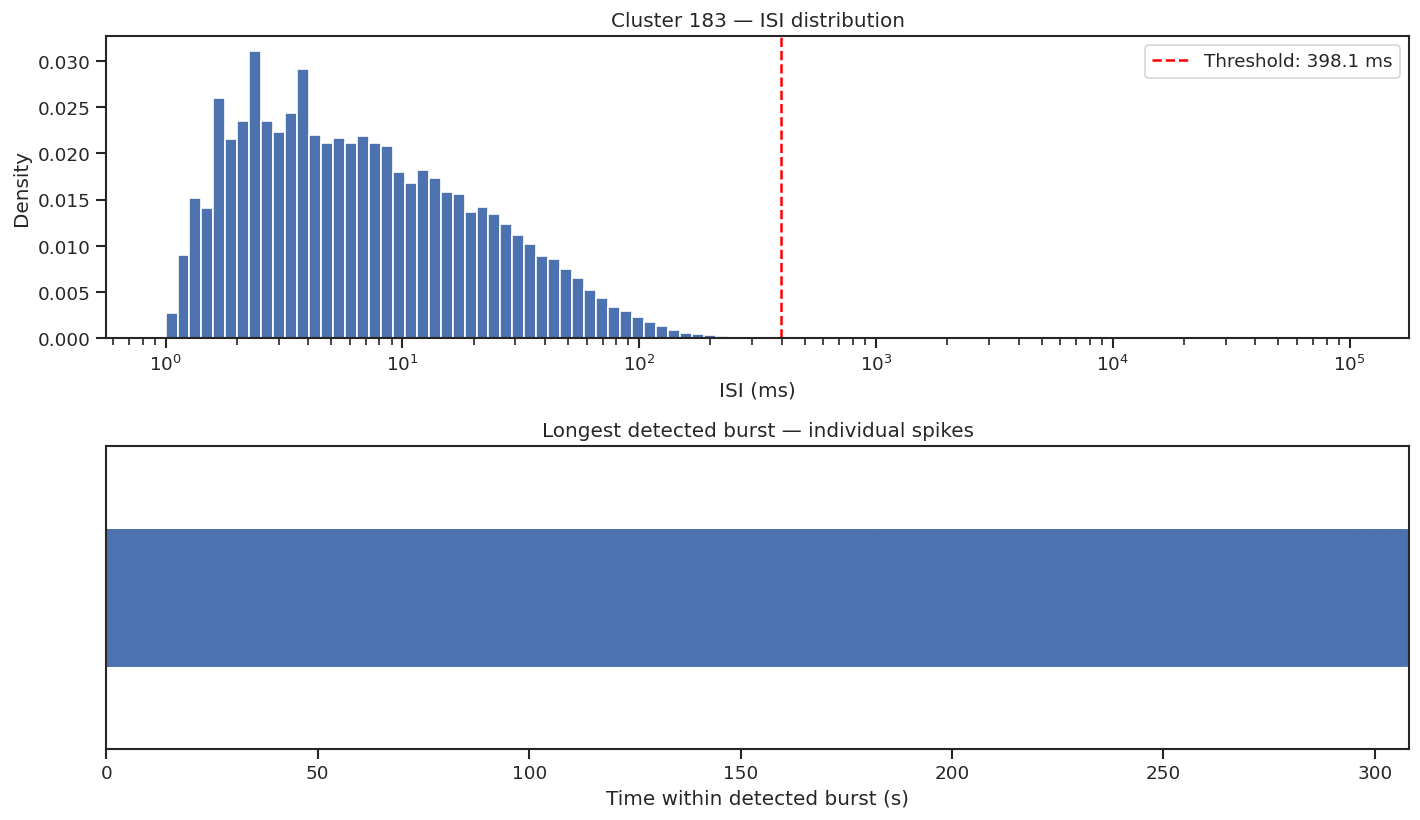

28181

In [27]:

# Inspect the spike train responsible for unusually long bursts.
# Diagnostic only — no files are modified.

loader = SpikeSortingLoader(pid=str(pilot.pid), one=one)
spikes, _, _ = loader.load_spike_sorting()

t = np.sort(
    np.asarray(spikes["times"])[
        np.asarray(spikes["clusters"]) == 183
    ]
)

bursts, threshold_ms, method = revised_logisi(t)
isi_ms = np.diff(t) * 1000

print("Cluster:", 183)
print("Spikes:", len(t))
print("Threshold:", round(threshold_ms, 2), "ms")
print("Method:", method)
print("Detected bursts:", len(bursts))

# Identify the longest detected burst.
s, e = max(bursts, key=lambda b: t[b[1]] - t[b[0]])

print("\nLONGEST BURST")
print("Duration:", round(t[e] - t[s], 3), "s")
print("Spikes:", e - s + 1)
print("Mean intraburst ISI:",
      round(np.diff(t[s:e + 1]).mean() * 1000, 2), "ms")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# Logarithmic ISI distribution.
axes[0].hist(
    isi_ms[isi_ms > 0],
    bins=np.logspace(0, 5, 100),
    density=True
)
axes[0].axvline(
    threshold_ms,
    color="red",
    linestyle="--",
    label=f"Threshold: {threshold_ms:.1f} ms"
)
axes[0].set_xscale("log")
axes[0].set_xlabel("ISI (ms)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].set_title("Cluster 183 — ISI distribution")

# Spike raster for the longest burst.
axes[1].eventplot(
    t[s:e + 1] - t[s],
    lineoffsets=0.5,
    linelengths=0.8
)
axes[1].set_xlim(0, t[e] - t[s])
axes[1].set_xlabel("Time within detected burst (s)")
axes[1].set_yticks([])
axes[1].set_title("Longest detected burst — individual spikes")

plt.tight_layout()
plt.show()

del spikes
gc.collect()


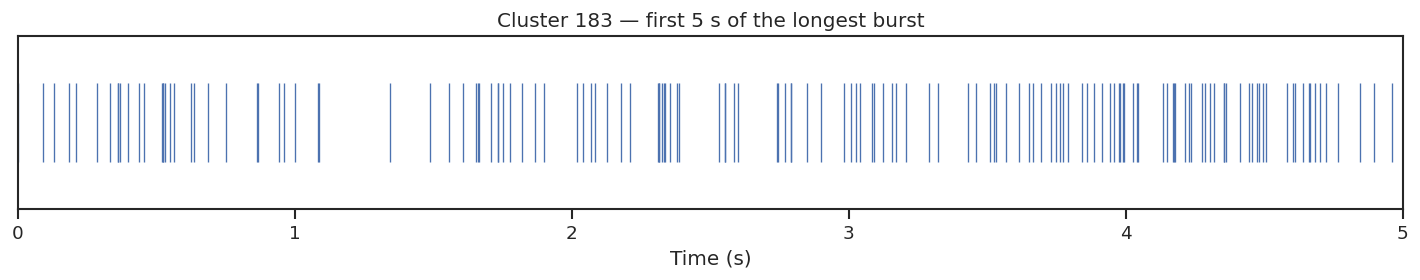

Spikes in 5 s: 148
Mean ISI (ms): 33.75
Median ISI (ms): 25.33
ISI > 100 ms (%): 5.44
ISI > 200 ms (%): 0.68


In [28]:

# Inspect a five-second segment of the longest detected burst.
# No files are modified.

segment_start = t[s]
segment_end = segment_start + 5.0

segment = t[
    (t >= segment_start) &
    (t < segment_end)
] - segment_start

segment_isi = np.diff(segment) * 1000

fig, ax = plt.subplots(figsize=(12, 2.5))

ax.eventplot(
    segment,
    lineoffsets=0.5,
    linelengths=0.8,
    linewidths=0.8
)

ax.set_xlim(0, 5)
ax.set_yticks([])
ax.set_xlabel("Time (s)")
ax.set_title("Cluster 183 — first 5 s of the longest burst")

plt.tight_layout()
plt.show()

print("Spikes in 5 s:", len(segment))
print("Mean ISI (ms):", round(np.mean(segment_isi), 2))
print("Median ISI (ms):", round(np.median(segment_isi), 2))
print("ISI > 100 ms (%):",
      round(100 * np.mean(segment_isi > 100), 2))
print("ISI > 200 ms (%):",
      round(100 * np.mean(segment_isi > 200), 2))


CLUSTER 183
---------------------------------------------
Spikes: 20779

PREVIOUS PYTHON
Threshold: 398.107 ms
Method: extended
Bursts: 49

REFERENCE-BASED PYTHON
Threshold: 719.686 ms
Method: extended
Detected histogram peaks: 3
Void parameter: 0.9369


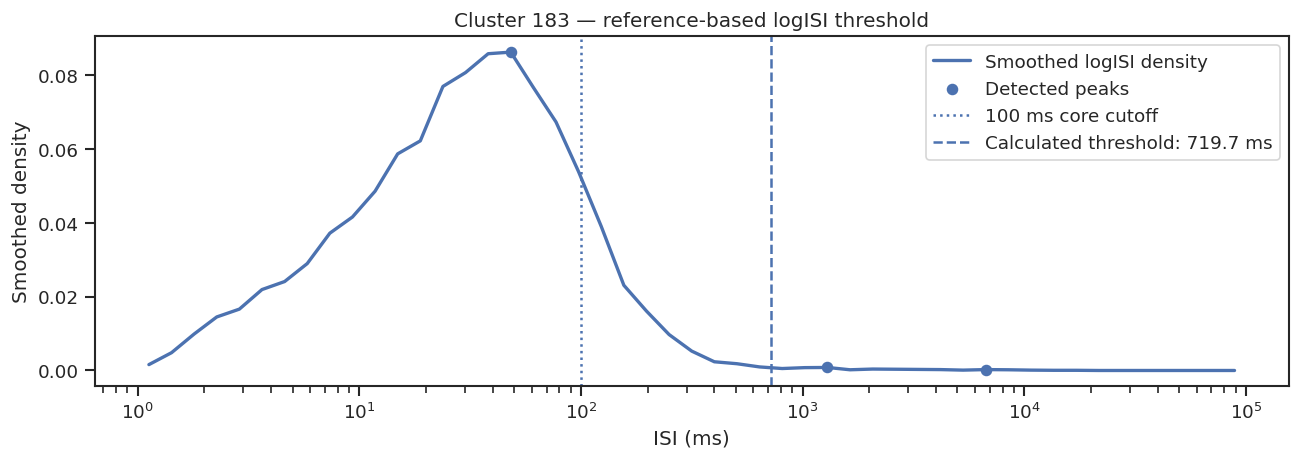


REFERENCE-BASED THRESHOLD TEST FINISHED
No files were modified.


In [29]:

# ============================================================
# CELL 03 — REFERENCE-BASED LOGISI THRESHOLD
#
# Based on:
# Pasquale et al. (2010)
# Cotterill & Eglen (2016)
# logisi_pasq_method.R (burstanalysis repository)
#
# This cell:
# - Recalculates the logISI threshold for cluster 183
# - Compares it with our previous Python implementation
# - Does not modify any saved data
#
# Note: LOWESS and histogram behavior may differ slightly
# between Python and the reference R implementation.
# ============================================================


def reference_logisi_threshold(times, cutoff_ms=100):
    """Python translation of the reference logISI threshold logic."""

    times = np.sort(np.asarray(times, dtype=float))
    isi_ms = np.diff(times) * 1000

    isi_ms = isi_ms[np.isfinite(isi_ms) & (isi_ms > 0)]

    if len(isi_ms) < 4:
        return np.nan, "insufficient_isi", None

    # Follow the reference: construct bins from all positive ISIs,
    # then exclude ISIs below 1 ms from the histogram.
    max_power = max(1, int(np.ceil(np.log10(isi_ms.max()))))
    n_edges = max(11, 10 * max_power)

    edges = np.logspace(0, max_power, n_edges)

    included = isi_ms[isi_ms >= 1]

    if len(included) < 4:
        return np.nan, "insufficient_isi", None

    counts, edges = np.histogram(included, bins=edges)
    density = counts.astype(float) / counts.sum()

    # Reference R code: lowess(density, f=0.05).
    smooth = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        it=3,
        return_sorted=False
    )

    # Reference-like local peak search, Pd=2.
    # Candidate must be higher than its immediate neighbors,
    # with separation between accepted peaks.
    peaks = []

    for j in range(2, len(smooth) - 2):
        local = smooth[j - 2:j + 3]

        if (
            smooth[j] > local[1]
            and smooth[j] > local[3]
            and smooth[j] >= local[0]
            and smooth[j] >= local[4]
        ):
            if not peaks or j - peaks[-1] >= 2:
                peaks.append(j)

    peaks = np.asarray(peaks, dtype=int)

    details = {
        "edges": edges,
        "density": density,
        "smooth": smooth,
        "peaks": peaks,
        "void": np.nan
    }

    if not len(peaks):
        return np.nan, "no_intraburst_peak", details

    peak_ms = edges[peaks]

    intraburst = peaks[peak_ms < cutoff_ms]

    if not len(intraburst):
        return np.nan, "no_intraburst_peak", details

    # Strongest peak below the cutoff.
    first = intraburst[np.argmax(smooth[intraburst])]

    later_peaks = peaks[peaks > first]

    if not len(later_peaks):
        return cutoff_ms, "core_100ms", details

    for second in later_peaks:

        valley = first + np.argmin(
            smooth[first:second + 1]
        )

        denominator = np.sqrt(
            smooth[first] * smooth[second]
        )

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void >= 0.7:

            threshold_ms = edges[valley]

            details["void"] = float(void)

            if threshold_ms >= 1000:
                return cutoff_ms, "core_100ms", details

            if threshold_ms > cutoff_ms:
                return threshold_ms, "extended", details

            return threshold_ms, "adaptive", details

    return cutoff_ms, "core_100ms", details


# ------------------------------------------------------------
# Run on the already loaded spike times of cluster 183
# ------------------------------------------------------------

old_bursts, old_threshold, old_method = revised_logisi(t)

new_threshold, new_method, info = reference_logisi_threshold(t)

print("CLUSTER 183")
print("-" * 45)
print("Spikes:", len(t))

print("\nPREVIOUS PYTHON")
print("Threshold:", round(old_threshold, 3), "ms")
print("Method:", old_method)
print("Bursts:", len(old_bursts))

print("\nREFERENCE-BASED PYTHON")
print("Threshold:", round(new_threshold, 3)
      if np.isfinite(new_threshold) else "Undefined", "ms")
print("Method:", new_method)

if info is not None:

    print("Detected histogram peaks:", len(info["peaks"]))
    print("Void parameter:",
          round(info["void"], 4)
          if np.isfinite(info["void"]) else "Not found")

    # Plot the actual smoothed logISI histogram.
    fig, ax = plt.subplots(figsize=(11, 4))

    centers = np.sqrt(
        info["edges"][:-1] * info["edges"][1:]
    )

    ax.plot(
        centers,
        info["smooth"],
        linewidth=2,
        label="Smoothed logISI density"
    )

    p = info["peaks"]

    if len(p):
        ax.scatter(
            centers[p],
            info["smooth"][p],
            s=35,
            label="Detected peaks",
            zorder=3
        )

    ax.axvline(
        100,
        linestyle=":",
        label="100 ms core cutoff"
    )

    if np.isfinite(new_threshold):
        ax.axvline(
            new_threshold,
            linestyle="--",
            label=f"Calculated threshold: {new_threshold:.1f} ms"
        )

    ax.set_xscale("log")
    ax.set_xlabel("ISI (ms)")
    ax.set_ylabel("Smoothed density")
    ax.set_title("Cluster 183 — reference-based logISI threshold")
    ax.legend()
    plt.tight_layout()
    plt.show()

print("\nREFERENCE-BASED THRESHOLD TEST FINISHED")
print("No files were modified.")


In [30]:
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
RESULTS = ROOT / "04_results"
RESULTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(META / "recovered_24_eligible_regions.csv")

genotypes = ["WT", "Fmr1", "Cntnap2", "Shank3B"]

# Anatomically defined regions for the primary analysis.
region_groups = {
    "DG": ["DG-mo", "DG-sg", "DG-po"],
    "CA1": ["CA1"],
    "CA3": ["CA3"],
    "VISp": ["VISp2/3", "VISp4", "VISp5", "VISp6a", "VISp6b"],
    "MOs": ["MOs2/3", "MOs5", "MOs6a"],
    "CP": ["CP"],
    "SUB": ["SUB"],
    "VL": ["VL"],
    "MRN": ["MRN"],
    "APN": ["APN"],
}

# Parent atlas labels and white-matter structures.
excluded_regions = ["HPF", "STR", "MB", "ccb", "cing", "dhc"]

records = []

for group, regions in region_groups.items():
    subset = df[df["region"].isin(regions)]

    row = {
        "region_group": group,
        "subregions": ", ".join(regions),
        "n_subregions": len(subset)
    }

    for genotype in genotypes:
        animals = subset[f"{genotype}_animals"]
        units = subset[f"{genotype}_units"]
        events = subset[f"{genotype}_complete_event_mice"]

        # Without mouse IDs, the exact union across
        # subregions cannot be calculated.
        row[f"{genotype}_mice_lower_bound"] = int(animals.max())
        row[f"{genotype}_units"] = int(units.sum())
        row[f"{genotype}_event_mice_lower_bound"] = int(events.max())

    row["min_mice_lower_bound"] = min(
        row[f"{g}_mice_lower_bound"] for g in genotypes
    )

    row["min_event_mice_lower_bound"] = min(
        row[f"{g}_event_mice_lower_bound"] for g in genotypes
    )

    records.append(row)

grouped = pd.DataFrame(records).sort_values(
    "min_mice_lower_bound", ascending=False
)

grouped["eligible_all_genotypes"] = (
    grouped["min_mice_lower_bound"] >= 5
)

# Save the new analysis matrix permanently.
grouped.to_csv(
    RESULTS / "anatomical_group_coverage.csv",
    index=False
)

df[df["region"].isin(excluded_regions)].to_csv(
    RESULTS / "excluded_atlas_labels.csv",
    index=False
)

display_cols = (
    ["region_group"]
    + [f"{g}_mice_lower_bound" for g in genotypes]
    + [f"{g}_units" for g in genotypes]
    + ["min_event_mice_lower_bound"]
)

print("ANATOMICAL GROUP COVERAGE")
display(grouped[display_cols])

print("\nELIGIBLE GROUPS:")
print(grouped.loc[
    grouped["eligible_all_genotypes"], "region_group"
].tolist())

print("\nSaved to:", RESULTS / "anatomical_group_coverage.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ANATOMICAL GROUP COVERAGE


,region_group,WT_mice_lower_bound,Fmr1_mice_lower_bound,Cntnap2_mice_lower_bound,Shank3B_mice_lower_bound,WT_units,Fmr1_units,Cntnap2_units,Shank3B_units,min_event_mice_lower_bound
0,DG,15,13,13,13,1654,2592,865,1552,12
1,CA1,13,11,11,14,1134,1495,1117,1879,11
2,CA3,11,10,10,9,568,324,771,666,8
4,MOs,12,12,8,7,1096,1519,986,979,6
5,CP,9,10,7,6,822,890,807,1070,5
8,MRN,9,11,6,7,2033,1136,1280,796,6
3,VISp,13,11,5,9,1285,1174,594,1039,5
6,SUB,8,10,6,5,808,1293,681,797,5
7,VL,7,8,5,7,131,154,172,567,5
9,APN,7,10,5,7,622,1000,314,586,5



ELIGIBLE GROUPS:
['DG', 'CA1', 'CA3', 'MOs', 'CP', 'MRN', 'VISp', 'SUB', 'VL', 'APN']

Saved to: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/anatomical_group_coverage.csv


In [32]:
folders = [
    Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis"),
    Path("/content/autism_anatomy_inventory"),
]

target_files = {
    "insertion_region_details.csv",
    "region_genotype_details.csv",
    "region_genotype_matrix.csv",
}

for folder in folders:
    print(f"\nChecking: {folder}")
    if not folder.exists():
        print("Not found")
        continue

    found = [
        p for p in folder.rglob("*.csv")
        if p.name in target_files
    ]

    for p in found:
        print("FOUND:", p)

    if not found:
        print("No detailed inventory files found")



Checking: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis
No detailed inventory files found

Checking: /content/autism_anatomy_inventory
Not found


In [33]:

ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
DOCS = ROOT / "00_documentation"

META.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

# Allen CCFv3 anatomical region dictionary.
region_text = """allen_acronym|full_name|macro_system|analysis_region|analysis_status
DG-mo|Dentate gyrus, molecular layer|Hippocampal formation|DG|include
DG-sg|Dentate gyrus, granule cell layer|Hippocampal formation|DG|include
DG-po|Dentate gyrus, polymorph layer|Hippocampal formation|DG|include
CA1|Field CA1|Hippocampal formation|CA1|include
CA3|Field CA3|Hippocampal formation|CA3|include
SUB|Subiculum|Hippocampal formation|SUB|include
VISp2/3|Primary visual area, layer 2/3|Cerebral cortex|VISp|include
VISp4|Primary visual area, layer 4|Cerebral cortex|VISp|include
VISp5|Primary visual area, layer 5|Cerebral cortex|VISp|include
VISp6a|Primary visual area, layer 6a|Cerebral cortex|VISp|include
VISp6b|Primary visual area, layer 6b|Cerebral cortex|VISp|include
MOs2/3|Secondary motor area, layer 2/3|Cerebral cortex|MOs|include
MOs5|Secondary motor area, layer 5|Cerebral cortex|MOs|include
MOs6a|Secondary motor area, layer 6a|Cerebral cortex|MOs|include
CP|Caudoputamen (dorsal striatum)|Striatum|CP|include
MRN|Midbrain reticular nucleus|Midbrain|MRN|include
APN|Anterior pretectal nucleus|Midbrain|APN|include
HPF|Hippocampal formation, unspecified|Unresolved parent label|UNRESOLVED_HPF|exclude_primary
STR|Striatum, unspecified|Unresolved parent label|UNRESOLVED_STR|exclude_primary
MB|Midbrain, unspecified|Unresolved parent label|UNRESOLVED_MB|exclude_primary
VL|Lateral ventricle|Ventricular system|NON_NEURAL|exclude
ccb|Corpus callosum, body|Fiber tracts|NON_NEURAL|exclude
cing|Cingulum bundle|Fiber tracts|NON_NEURAL|exclude
dhc|Dorsal hippocampal commissure|Fiber tracts|NON_NEURAL|exclude
"""

atlas = pd.read_csv(StringIO(region_text), sep="|")

# Save the anatomical dictionary.
atlas.to_csv(META / "allen_region_dictionary.csv", index=False)

# Read the previously recovered region counts.
coverage = pd.read_csv(
    META / "recovered_24_eligible_regions.csv"
)

# Attach region labels without changing original counts.
annotated = coverage.merge(
    atlas,
    left_on="region",
    right_on="allen_acronym",
    how="left",
    validate="one_to_one"
)

annotated.to_csv(
    META / "annotated_region_coverage.csv",
    index=False
)

# Save the analysis plan.
plan = """# Electrophysiological reanalysis plan

Dataset: angelaki_mouseASD
Genotypes: WT, Fmr1, Cntnap2, Shank3B

Primary neuronal regions:
DG, CA1, CA3, SUB, VISp, MOs, CP, MRN, APN.

1. Recover mouse/session/probe/cluster identifiers and Allen labels.
2. Merge anatomical sublayers at the individual-cluster level.
3. Select QC-pass neuronal units and report unique mouse coverage.
4. Calculate firing rate, ISI CV and CV2.
5. Quantify bursting and pause characteristics.
6. Analyze stimulus-, movement- and feedback-aligned activity.
7. Compare each ASD genotype with WT.
8. Assess shared and genotype-specific abnormalities.

Statistics:
Mouse is the biological replicate.
Retain neuron, probe and session identifiers.
Report effect sizes, confidence intervals and adjusted p-values.
Apply multiple-comparison correction to confirmatory tests.

Important:
VL denotes lateral ventricle, not ventrolateral thalamus.
White matter and unspecified parent regions are excluded
from primary neuronal comparisons.

All long computations must save checkpoints to Google Drive.
"""

(DOCS / "ANALYSIS_PLAN.md").write_text(plan, encoding="utf-8")

print("Saved anatomical dictionary:", len(atlas), "labels")
print("Primary neuronal regions:",
      atlas.loc[atlas.analysis_status == "include",
                "analysis_region"].nunique())
print("Saved annotated coverage and analysis plan.")

display(atlas)


Saved anatomical dictionary: 24 labels
Primary neuronal regions: 9
Saved annotated coverage and analysis plan.


,allen_acronym,full_name,macro_system,analysis_region,analysis_status
0,DG-mo,"Dentate gyrus, molecular layer",Hippocampal formation,DG,include
1,DG-sg,"Dentate gyrus, granule cell layer",Hippocampal formation,DG,include
2,DG-po,"Dentate gyrus, polymorph layer",Hippocampal formation,DG,include
3,CA1,Field CA1,Hippocampal formation,CA1,include
4,CA3,Field CA3,Hippocampal formation,CA3,include
5,SUB,Subiculum,Hippocampal formation,SUB,include
6,VISp2/3,"Primary visual area, layer 2/3",Cerebral cortex,VISp,include
7,VISp4,"Primary visual area, layer 4",Cerebral cortex,VISp,include
8,VISp5,"Primary visual area, layer 5",Cerebral cortex,VISp,include
9,VISp6a,"Primary visual area, layer 6a",Cerebral cortex,VISp,include


In [34]:
ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
META.mkdir(parents=True, exist_ok=True)

one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

# Retrieve probe insertions belonging to the ASD dataset.
insertions = one.alyx.rest(
    "insertions",
    "list",
    django="session__projects__name,angelaki_mouseASD"
)

records = []

for insertion in insertions:
    session = insertion.get("session")
    if not isinstance(session, dict):
        continue

    subject = session.get("subject", "")
    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject)
    prefix = subject.split("-")[0].upper()

    genotype = {
        "NYU": "WT",
        "FMR": "Fmr1",
        "CSP": "Cntnap2",
        "SH": "Shank3B"
    }.get(prefix)

    if genotype is None:
        continue

    records.append({
        "pid": insertion["id"],
        "eid": session["id"],
        "probe": insertion.get("name"),
        "subject": subject,
        "genotype": genotype
    })

inventory = pd.DataFrame(
    records,
    columns=["pid", "eid", "probe", "subject", "genotype"]
).drop_duplicates(subset=["pid"])

inventory.to_csv(META / "mouse_probe_inventory.csv", index=False)

print("Total probe insertions:", len(inventory))
print("Unique mice:", inventory["subject"].nunique())
display(inventory.groupby("genotype").agg(
    mice=("subject", "nunique"),
    probes=("pid", "nunique")
))
print("Saved:", META / "mouse_probe_inventory.csv")


Total probe insertions: 0
Unique mice: 0


,mice,probes
genotype,,


Saved: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/02_session_metadata/mouse_probe_inventory.csv


In [ ]:
ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"

one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

project = "angelaki_mouseASD"

# Retrieve all insertions and sessions from the project.
insertions = one.alyx.rest(
    "insertions", "list",
    django=f"session__projects__name,{project}"
)

sessions = one.alyx.rest(
    "sessions", "list",
    django=f"projects__name,{project}"
)

def get_id(value):
    if isinstance(value, dict):
        value = value.get("id", "")
    return str(value).rstrip("/").split("/")[-1]

# Match session UUIDs with subject information.
session_lookup = {
    get_id(s["id"]): s for s in sessions
}

genotype_map = {
    "NYU": "WT",
    "FMR": "Fmr1",
    "CSP": "Cntnap2",
    "SH": "Shank3B"
}

records = []

for ins in insertions:
    eid = get_id(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")
    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject)
    genotype = genotype_map.get(subject.split("-")[0].upper())

    if genotype is None:
        continue

    records.append({
        "pid": ins["id"],
        "eid": eid,
        "probe": ins.get("name"),
        "subject": subject,
        "genotype": genotype
    })

inventory = pd.DataFrame(
    records,
    columns=["pid", "eid", "probe", "subject", "genotype"]
).drop_duplicates("pid")

# Never overwrite the saved inventory with an empty result.
if inventory.empty:
    raise RuntimeError(
        f"No matching insertions. "
        f"Insertions returned: {len(insertions)}, "
        f"sessions returned: {len(sessions)}."
    )

inventory.to_csv(
    META / "mouse_probe_inventory.csv",
    index=False
)

print("Total insertions:", len(inventory))
print("Unique mice:", inventory.subject.nunique())

display(
    inventory.groupby("genotype").agg(
        mice=("subject", "nunique"),
        insertions=("pid", "nunique")
    )
)

print("Inventory saved successfully.")


Total insertions: 99
Unique mice: 15


,mice,insertions
genotype,,
WT,15,99


Inventory saved successfully.


In [ ]:

# Restore genotype assignments from the original behavioral lists.

BEHAVIOUR = ROOT.parent / "Behaviour"

source_files = {
    "WT": "behavior_list_NYU.xlsx",
    "Fmr1": "behavior_list_FMR.xlsx",
    "Cntnap2": "behavior_list_CSP.xlsx",
    "Shank3B": "behavior_list_SH.xlsx",
}

subject_to_genotype = {}

for genotype, filename in source_files.items():
    sheet = pd.read_excel(BEHAVIOUR / filename, header=None)

    # Animal identifiers are in the first column.
    subjects = (
        sheet.iloc[:, 0]
        .dropna()
        .astype(str)
        .str.strip()
    )

    for subject in subjects:
        if subject in subject_to_genotype:
            if subject_to_genotype[subject] != genotype:
                raise ValueError(
                    f"Conflicting genotype assignment: {subject}"
                )
        subject_to_genotype[subject] = genotype

    print(f"{genotype}: {subjects.nunique()} listed animals")

# Use the complete Alyx session list retrieved previously.
session_lookup = {
    get_id(s["id"]): s for s in sessions
}

records = []

for ins in insertions:
    eid = get_id(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")

    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject).strip()
    genotype = subject_to_genotype.get(subject)

    if genotype is None:
        continue

    records.append({
        "pid": ins["id"],
        "eid": eid,
        "probe": ins.get("name"),
        "subject": subject,
        "genotype": genotype
    })

full_inventory = pd.DataFrame(records).drop_duplicates("pid")

summary = full_inventory.groupby("genotype").agg(
    mice=("subject", "nunique"),
    insertions=("pid", "nunique")
).reindex(["WT", "Fmr1", "Cntnap2", "Shank3B"])

print("\nRESTORED DATASET")
display(summary)

print("Total insertions:", len(full_inventory))
print("Unique mice:", full_inventory.subject.nunique())

# Save only if all four genotypes were recovered.
if full_inventory.genotype.nunique() == 4:
    full_inventory.to_csv(
        META / "mouse_probe_inventory.csv",
        index=False
    )
    print("Full inventory saved.")
else:
    print("Incomplete matching — previous inventory preserved.")
    print("Unmatched session subjects:")
    unmatched = sorted({
        str(s.get("subject", ""))
        for s in sessions
        if str(s.get("subject", "")) not in subject_to_genotype
    })
    print(unmatched[:30])


WT: 15 listed animals
Fmr1: 25 listed animals
Cntnap2: 25 listed animals
Shank3B: 22 listed animals

RESTORED DATASET


,mice,insertions
genotype,,
WT,15,99
Fmr1,15,105
Cntnap2,16,85
Shank3B,16,75


Total insertions: 364
Unique mice: 62
Full inventory saved.


In [ ]:

!echo "=== DISK ==="
!df -h /content

!echo "=== RAM ==="
!free -h

!echo "=== IBL CACHE ==="
!du -sh /root/Downloads/ONE 2>/dev/null


=== DISK ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  1.9G  106G   2% /
=== RAM ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.8Gi       6.8Gi       5.0Mi       4.4Gi        10Gi
Swap:             0B          0B          0B
=== IBL CACHE ===
1.3G	/root/Downloads/ONE


In [ ]:

# WT analysis: all insertions, 24 original regions.
# Each insertion is checkpointed immediately to Google Drive.

OUTPUT = ROOT / "03_processed_data" / "WT"
OUTPUT.mkdir(parents=True, exist_ok=True)

WT = pd.read_csv(META / "mouse_probe_inventory.csv")
WT = WT.loc[WT["genotype"] == "WT"].copy()

atlas = pd.read_csv(META / "allen_region_dictionary.csv")
region_map = atlas.set_index("allen_acronym")["analysis_region"].to_dict()
valid_regions = set(atlas["allen_acronym"])

assert WT.subject.nunique() == 15
assert len(WT) == 99

# LogISI burst detection: individual ISI distributions.
# Pasquale et al. (2010); Cotterill et al. (2016).
def logisi_bursts(t, max_isi=0.100, min_spikes=3):
    isi = np.diff(t)
    positive = isi[isi > 0]

    if len(positive) < 3:
        return [], np.nan

    log_values = np.log10(positive * 1000)
    edges = np.arange(
        np.floor(log_values.min() * 10) / 10,
        np.ceil(log_values.max() * 10) / 10 + 0.11,
        0.1
    )
    if len(edges) < 4:
        return [], np.nan

    counts, edges = np.histogram(log_values, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2
    smooth = np.convolve(counts, np.ones(3) / 3, mode="same")

    peaks, _ = find_peaks(smooth)
    early = peaks[(10 ** centers[peaks]) <= max_isi * 1000]

    if len(early) == 0:
        return [], np.nan

    first = early[np.argmax(smooth[early])]
    cutoff = max_isi

    for second in peaks[peaks > first]:
        valley = first + np.argmin(smooth[first:second + 1])
        denominator = np.sqrt(smooth[first] * smooth[second])

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void > 0.7:
            cutoff = min(10 ** centers[valley] / 1000, max_isi)
            break

    short = (isi > 0) & (isi < cutoff)

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )
    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    bursts = [
        (int(s), int(e))
        for s, e in zip(starts, ends)
        if e - s + 1 >= min_spikes
    ]

    return bursts, cutoff * 1000


def compute_metrics(t, duration):
    t = np.sort(np.asarray(t, dtype=float))
    isi = np.diff(t)
    positive = isi[isi > 0]
    bursts, threshold = logisi_bursts(t)

    result = {
        "n_spikes": len(t),
        "fr_hz": len(t) / duration,
        "mean_isi_ms": np.mean(positive) * 1000
            if len(positive) else np.nan,
        "cv_isi": np.std(positive) / np.mean(positive)
            if len(positive) >= 3 else np.nan,
        "cv2": np.mean(
            2 * np.abs(np.diff(positive)) /
            (positive[:-1] + positive[1:])
        ) if len(positive) >= 3 else np.nan,
        "logisi_threshold_ms": threshold,
        "burst_rate_min": len(bursts) * 60 / duration,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan,
    }

    if bursts:
        counts = np.array([e - s + 1 for s, e in bursts])
        lengths = np.array([t[e] - t[s] for s, e in bursts])

        result["burst_fraction_pct"] = (
            100 * counts.sum() / len(t)
        )
        result["burst_duration_ms"] = 1000 * lengths.mean()
        result["spikes_per_burst"] = counts.mean()
        result["intraburst_hz"] = np.mean(
            (counts - 1) / lengths
        )

        if len(bursts) > 1:
            gaps = [
                t[bursts[i + 1][0]] - t[bursts[i][1]]
                for i in range(len(bursts) - 1)
            ]
            result["interburst_interval_s"] = np.mean(gaps)

    return result


def process_insertion(rec):
    loader = SpikeSortingLoader(pid=str(rec.pid), one=one)
    spikes, clusters, channels = loader.load_spike_sorting()
    clusters = loader.merge_clusters(spikes, clusters, channels)

    times = np.asarray(spikes["times"])
    ids = np.asarray(spikes["clusters"])
    duration = float(times.max() - times.min())

    if duration <= 0:
        raise ValueError("Invalid recording duration")

    labels = np.asarray(clusters["label"])
    acronyms = np.asarray(clusters["acronym"])
    cluster_ids = np.asarray(
        clusters.get("cluster_id", np.arange(len(labels)))
    )

    if not (len(labels) == len(acronyms) == len(cluster_ids)):
        raise ValueError("Cluster metadata length mismatch")

    # Group spike times by cluster only once.
    order = np.argsort(ids, kind="stable")
    sorted_ids = ids[order]
    sorted_times = times[order]
    unique, starts, counts = np.unique(
        sorted_ids, return_index=True, return_counts=True
    )
    spike_ranges = {
        int(cid): (int(s), int(n))
        for cid, s, n in zip(unique, starts, counts)
    }

    rows = []

    for i, cid in enumerate(cluster_ids):
        if labels[i] != 1:
            continue

        acronym = str(acronyms[i])
        if acronym not in valid_regions:
            continue

        bounds = spike_ranges.get(int(cid))
        if bounds is None:
            continue

        start, count = bounds
        if count < 100:
            continue

        unit_times = sorted_times[start:start + count]
        metrics = compute_metrics(unit_times, duration)

        rows.append({
            "subject": rec.subject,
            "genotype": "WT",
            "eid": rec.eid,
            "pid": rec.pid,
            "probe": rec.probe,
            "cluster_id": int(cid),
            "original_region": acronym,
            "region": region_map[acronym],
            "duration_s": duration,
            **metrics
        })

    return pd.DataFrame(rows)


# Process all WT insertions, resuming from saved files.
log_file = OUTPUT / "processing_log.csv"
logs = (
    pd.read_csv(log_file)
    if log_file.exists()
    else pd.DataFrame(columns=["pid", "status", "neurons", "error"])
)

completed = set(
    logs.loc[
        logs["status"] == "completed", "pid"
    ].astype(str)
)

for number, rec in enumerate(WT.itertuples(index=False), 1):
    pid = str(rec.pid)
    target = OUTPUT / f"{pid}.csv"

    if pid in completed and target.exists():
        continue

    print(f"[{number}/{len(WT)}] {rec.subject} | {rec.probe}")

    try:
        units = process_insertion(rec)

        # An insertion with zero eligible units is still completed.
        if units.empty:
            pd.DataFrame(
                columns=["subject", "genotype", "pid", "region"]
            ).to_csv(target, index=False)
        else:
            units.to_csv(target, index=False)

        logs = logs[logs.pid.astype(str) != pid]
        logs = pd.concat([
            logs,
            pd.DataFrame([{
                "pid": pid,
                "status": "completed",
                "neurons": len(units),
                "error": ""
            }])
        ], ignore_index=True)

        print("Saved neurons:", len(units))

    except Exception as exc:
        logs = logs[logs.pid.astype(str) != pid]
        logs = pd.concat([
            logs,
            pd.DataFrame([{
                "pid": pid,
                "status": "error",
                "neurons": 0,
                "error": str(exc)[:300]
            }])
        ], ignore_index=True)

        print("ERROR:", str(exc)[:200])

    logs.to_csv(log_file, index=False)


# Collect saved neuron-level results.
files = [OUTPUT / f"{pid}.csv" for pid in WT.pid.astype(str)]
parts = []

for path in files:
    if path.exists():
        part = pd.read_csv(path)
        if "fr_hz" in part.columns:
            parts.append(part)

if not parts:
    print("No neurons available yet. Inspect processing_log.csv.")
else:
    neurons = pd.concat(parts, ignore_index=True)
    neurons.to_csv(OUTPUT / "WT_all_neurons.csv", index=False)

    parameters = [
        "fr_hz", "mean_isi_ms", "cv_isi", "cv2",
        "burst_rate_min", "burst_fraction_pct",
        "burst_duration_ms", "spikes_per_burst",
        "intraburst_hz", "interburst_interval_s"
    ]

    # First summarize neurons within individual mice.
    mouse_means = neurons.groupby(
        ["original_region", "subject"],
        as_index=False
    )[parameters].mean()

    # Then calculate group-level averages across mice.
    summary = mouse_means.groupby("original_region")[
        parameters
    ].mean()

    n_mice = mouse_means.groupby(
        "original_region"
    )["subject"].nunique()

    n_neurons = neurons.groupby(
        "original_region"
    ).size()

    summary.insert(0, "n_mice", n_mice)
    summary.insert(1, "n_neurons", n_neurons)

    # Preserve all 24 anatomical labels, even if no units passed QC.
    summary = summary.reindex(atlas["allen_acronym"])
    summary.index.name = "Anatomical region"

    summary.to_csv(OUTPUT / "WT_region_summary.csv")

    print("\nWT REGION SUMMARY")
    display(summary.round(3))

    print("\nSaved:")
    print(OUTPUT / "WT_all_neurons.csv")
    print(OUTPUT / "WT_region_summary.csv")
    print(OUTPUT / "processing_log.csv")


[1/99] NYU-58 | probe00
Saved neurons: 13
[2/99] NYU-58 | probe01
Saved neurons: 26
[3/99] NYU-58 | probe00
Saved neurons: 44
[4/99] NYU-58 | probe01
Saved neurons: 22
[5/99] NYU-58 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 134M/134M [00:04<00:00, 30.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 67.1M/67.1M [00:01<00:00, 60.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 134M/134M [00:02<00:00, 63.4MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 134M/134M [00:01<00:00, 67.7MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 3.41k/3.41k [00:00<00:00, 8.13kB/s]
(S3) /root/Do

Saved neurons: 23
[6/99] NYU-58 | probe01


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.depths.npy: 100%|██████████| 93.7M/93.7M [00:04<00:00, 22.6MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.times.npy: 100%|██████████| 93.7M/93.7M [00:01<00:00, 47.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.clusters.npy: 100%|██████████| 46.9M/46.9M [00:01<00:00, 44.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.amps.npy: 100%|██████████| 93.7M/93.7M [00:01<00:00, 50.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/clusters.channels.npy: 100%|██████████| 3.82k/3.82k [00:00<00:00, 9.11kB/s]
(S3) /r

Saved neurons: 23
[7/99] NYU-58 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 115M/115M [00:03<00:00, 29.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 57.5M/57.5M [00:01<00:00, 52.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 115M/115M [00:01<00:00, 59.3MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 115M/115M [00:01<00:00, 60.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 3.54k/3.54k [00:00<00:00, 7.88kB/s]
(S3) /root/Do

... (183 outputs left out)

(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.amps.npy: 100%|██████████| 23.1M/23.1M [00:02<00:00, 8.83MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.clusters.npy: 100%|██████████| 11.6M/11.6M [00:01<00:00, 10.8MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.times.npy: 100%|██████████| 23.1M/23.1M [00:01<00:00, 22.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.depths.npy: 100%|██████████| 23.1M/23.1M [00:00<00:00, 25.0MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/clusters.depths.npy: 100%|██████████| 888/888 [00:00<00:00, 2.06kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelaki

Saved neurons: 1

WT REGION SUMMARY


,n_mice,n_neurons,fr_hz,mean_isi_ms,cv_isi,cv2,burst_rate_min,burst_fraction_pct,burst_duration_ms,spikes_per_burst,intraburst_hz,interburst_interval_s
Anatomical region,,,,,,,,,,,,
DG-mo,15,124,4.096,1195.440,6.855,1.015,21.630,56.846,251.487,16.184,95.511,51.653
DG-sg,12,69,5.952,705.583,4.790,1.018,32.504,55.319,188.692,6.942,55.127,6.314
DG-po,5,30,2.912,1462.607,3.675,1.178,18.561,49.220,105.430,5.227,81.455,17.762
CA1,13,212,5.148,1814.380,4.880,0.874,21.052,48.793,4125.548,470.145,75.306,26.347
CA3,8,121,5.263,1808.788,4.099,0.991,25.609,50.056,187.327,7.349,73.950,16.369
SUB,9,166,6.163,790.943,5.464,0.935,25.104,52.555,292.059,11.442,60.007,11.790
VISp2/3,6,16,4.891,2224.188,8.013,0.865,17.129,51.373,301.440,16.097,77.894,5.547
VISp4,5,12,6.713,616.959,21.418,0.937,21.485,73.962,409.328,18.433,53.398,4.541
VISp5,6,45,5.070,1096.231,10.654,0.812,11.887,49.437,8038.841,925.214,74.220,56.428



Saved:
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/WT_all_neurons.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/WT_region_summary.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/processing_log.csv


In [ ]:

!echo "=== DISK ==="
!df -h /content

!echo "=== RAM ==="
!free -h

!echo "=== IBL CACHE ==="
!du -sh /root/Downloads/ONE 2>/dev/null


=== DISK ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   19G   90G  18% /
=== RAM ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.5Gi       6.5Gi       5.1Mi       4.1Gi        10Gi
Swap:             0B          0B          0B
=== IBL CACHE ===
18G	/root/Downloads/ONE


In [37]:

# Restore WT inventory from the saved master CSV.
# No data files are modified.

inventory = pd.read_csv(
    META / "mouse_probe_inventory.csv"
)

inventory["genotype"] = (
    inventory["genotype"].astype(str).str.strip()
)


# Restore WT insertion list directly from completed processing records.
# The master inventory CSV is currently empty.
# No files are created or overwritten.

WT_DIR = ROOT / "03_processed_data" / "WT"

log = pd.read_csv(WT_DIR / "processing_log.csv")
log = log.loc[log["status"] == "completed"].copy()

records = []

for pid in log["pid"].astype(str).unique():
    path = WT_DIR / f"{pid}.csv"

    if not path.exists():
        raise FileNotFoundError(f"Missing insertion CSV: {pid}")

    data = pd.read_csv(path)

    records.append({
        "pid": pid,
        "subject": (
            str(data["subject"].iloc[0])
            if len(data) and "subject" in data
            else "WT_empty"
        ),
        "probe": (
            str(data["probe"].iloc[0])
            if len(data) and "probe" in data
            else "unknown"
        ),
        "genotype": "WT"
    })

wt_inventory = pd.DataFrame(records)

print("Restored insertions:", len(wt_inventory))
print("Existing files:", sum(
    (WT_DIR / f"{pid}.csv").exists()
    for pid in wt_inventory["pid"]
))
print("Insertions with neurons:", sum(
    pd.read_csv(WT_DIR / f"{pid}.csv").shape[0] > 0
    for pid in wt_inventory["pid"]
))

assert len(wt_inventory) == 99

print("WT insertion list successfully restored.")


WT_DIR = ROOT / "03_processed_data" / "WT"

print("All insertions:", len(inventory))
print("Genotypes:", inventory["genotype"].value_counts().to_dict())
print("WT mice:", wt_inventory["subject"].nunique())
print("WT insertions:", len(wt_inventory))

available = sum(
    (WT_DIR / f"{pid}.csv").exists()
    for pid in wt_inventory["pid"]
)

print("Existing WT insertion CSVs:", available)

assert len(wt_inventory) == 99, "WT inventory is incomplete"
assert available == 99, "Some WT files are missing"

print("\nWT inventory restored successfully.")


Restored insertions: 99
Existing files: 99
Insertions with neurons: 95
WT insertion list successfully restored.
All insertions: 0
Genotypes: {}
WT mice: 16
WT insertions: 99
Existing WT insertion CSVs: 99

WT inventory restored successfully.


In [40]:
gc.collect()

0

In [41]:
import shutil

cache_dir = Path("/root/Downloads/ONE")

print("Cache exists:", cache_dir.exists())

if cache_dir.exists():
    shutil.rmtree(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

print("ONE cache cleared.")

Cache exists: True
ONE cache cleared.


In [42]:

# ============================================================
# WT vs FMR1 — MOUSE-LEVEL STATISTICAL COMPARISON
#
# - Rebuild WT 9-region summary
# - Aggregate individual neurons at mouse level
# - Compare independent WT and Fmr1 mice
# - Welch's independent-samples t-test
# - Benjamini-Hochberg FDR correction across 90 tests
# - Save all results to existing project directories
#
# No raw spike data required.
# No original neuron files are modified.
# ============================================================

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

WT_DIR = ROOT / "03_processed_data" / "WT"
FMR_DIR = ROOT / "03_processed_data" / "Fmr1"
RESULTS_DIR = ROOT / "04_results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REGIONS = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

METRICS = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]

# ------------------------------------------------------------
# 1. LOAD ALREADY PROCESSED NEURON-LEVEL DATA
# ------------------------------------------------------------

wt = pd.read_csv(WT_DIR / "WT_all_neurons.csv")
fmr = pd.read_csv(FMR_DIR / "Fmr1_all_neurons.csv")

assert len(wt) == 2436, "Unexpected WT neuron count"
assert len(fmr) == 2720, "Unexpected Fmr1 neuron count"

assert wt["subject"].nunique() == 15
assert fmr["subject"].nunique() == 15

assert wt["genotype"].eq("WT").all()
assert fmr["genotype"].eq("Fmr1").all()

print("WT:", len(wt), "neurons")
print("Fmr1:", len(fmr), "neurons")


# ------------------------------------------------------------
# 2. COMBINE BOTH GROUPS
# ------------------------------------------------------------

neurons = pd.concat(
    [wt, fmr],
    ignore_index=True
)

# Use the same 9-region grouping for both genotypes.
REGION_MAP = {
    "DG-mo": "DG",
    "DG-sg": "DG",
    "DG-po": "DG",
    "CA1": "CA1",
    "CA3": "CA3",
    "SUB": "SUB",
    "VISp2/3": "VISp",
    "VISp4": "VISp",
    "VISp5": "VISp",
    "VISp6a": "VISp",
    "VISp6b": "VISp",
    "MOs2/3": "MOs",
    "MOs5": "MOs",
    "MOs6a": "MOs",
    "CP": "CP",
    "MRN": "MRN",
    "APN": "APN"
}

neurons["analysis_region"] = (
    neurons["original_region"].map(REGION_MAP)
)

primary = neurons.loc[
    neurons["analysis_region"].isin(REGIONS)
].copy()

# ------------------------------------------------------------
# 3. AVERAGE NEURONS WITHIN EACH MOUSE AND REGION
# ------------------------------------------------------------

mouse_data = (
    primary
    .groupby(
        ["genotype", "subject", "analysis_region"],
        as_index=False
    )
    .agg(
        n_neurons=("cluster_id", "size"),
        **{
            metric: (metric, "mean")
            for metric in METRICS
        }
    )
)

# Save mouse-level observations for reproducibility.
MOUSE_PATH = RESULTS_DIR / "WT_Fmr1_mouse_level.csv"

mouse_data.to_csv(MOUSE_PATH, index=False)

print("\nMouse-level records:", len(mouse_data))
print("Saved:", MOUSE_PATH.name)


# ------------------------------------------------------------
# 4. REBUILD WT NINE-REGION SUMMARY
# ------------------------------------------------------------

def make_region_summary(genotype):

    group = mouse_data.loc[
        mouse_data["genotype"] == genotype
    ].copy()

    summary = (
        group.groupby("analysis_region")[METRICS]
        .mean()
        .reindex(REGIONS)
    )

    n_mice = (
        group.groupby("analysis_region")["subject"]
        .nunique()
    )

    n_neurons = (
        group.groupby("analysis_region")["n_neurons"]
        .sum()
    )

    summary.insert(
        0, "n_mice",
        n_mice.reindex(REGIONS)
    )

    summary.insert(
        1, "n_neurons",
        n_neurons.reindex(REGIONS)
    )

    summary.index.name = "Anatomical region"

    return summary.reset_index()


wt_summary = make_region_summary("WT")
fmr_summary = make_region_summary("Fmr1")

wt_summary.to_csv(
    WT_DIR / "WT_9_region_summary.csv",
    index=False
)

# Update the existing Fmr1 summary to guarantee identical
# aggregation and column order across both groups.
fmr_summary.to_csv(
    FMR_DIR / "Fmr1_9_region_summary.csv",
    index=False
)

print("Saved WT_9_region_summary.csv")
print("Saved Fmr1_9_region_summary.csv")


# ------------------------------------------------------------
# 5. WELCH T-TEST: INDEPENDENT MICE
# ------------------------------------------------------------

results = []

for region in REGIONS:

    for metric in METRICS:

        a = mouse_data.loc[
            (mouse_data["genotype"] == "WT") &
            (mouse_data["analysis_region"] == region),
            metric
        ].dropna().to_numpy(dtype=float)

        b = mouse_data.loc[
            (mouse_data["genotype"] == "Fmr1") &
            (mouse_data["analysis_region"] == region),
            metric
        ].dropna().to_numpy(dtype=float)

        if len(a) >= 2 and len(b) >= 2:

            test = ttest_ind(
                a,
                b,
                equal_var=False
            )

            t_stat = float(test.statistic)
            p_raw = float(test.pvalue)

        else:
            t_stat = np.nan
            p_raw = np.nan

        mean_wt = np.mean(a) if len(a) else np.nan
        mean_fmr = np.mean(b) if len(b) else np.nan

        results.append({
            "region": region,
            "metric": metric,
            "n_WT_mice": len(a),
            "n_Fmr1_mice": len(b),
            "WT_mean": mean_wt,
            "WT_SD": np.std(a, ddof=1) if len(a) > 1 else np.nan,
            "Fmr1_mean": mean_fmr,
            "Fmr1_SD": np.std(b, ddof=1) if len(b) > 1 else np.nan,
            "difference_Fmr1_minus_WT": mean_fmr - mean_wt,
            "t_statistic": t_stat,
            "p_raw": p_raw
        })


results_df = pd.DataFrame(results)


# ------------------------------------------------------------
# 6. BENJAMINI-HOCHBERG FDR CORRECTION
# ------------------------------------------------------------

results_df["p_FDR"] = np.nan

valid = results_df["p_raw"].notna()

if valid.any():

    _, corrected, _, _ = multipletests(
        results_df.loc[valid, "p_raw"],
        alpha=0.05,
        method="fdr_bh"
    )

    results_df.loc[valid, "p_FDR"] = corrected

results_df["significant_raw"] = (
    results_df["p_raw"] < 0.05
)

results_df["significant_FDR"] = (
    results_df["p_FDR"] < 0.05
)


# ------------------------------------------------------------
# 7. SAVE COMPARATIVE RESULTS
# ------------------------------------------------------------

RESULTS_PATH = (
    RESULTS_DIR / "WT_vs_Fmr1_Welch_results.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

print("\n" + "=" * 60)
print("WT vs FMR1 — STATISTICAL RESULTS")
print("=" * 60)

print("Total tests:", len(results_df))

print(
    "Raw p < 0.05:",
    int(results_df["significant_raw"].sum())
)

print(
    "FDR-adjusted p < 0.05:",
    int(results_df["significant_FDR"].sum())
)

print("\nRESULTS SORTED BY P-VALUE")

display(
    results_df
    .sort_values("p_raw")
    .head(20)
    .round(5)
)

print("\nFILES SAVED:")
print(WT_DIR / "WT_9_region_summary.csv")
print(FMR_DIR / "Fmr1_9_region_summary.csv")
print(MOUSE_PATH)
print(RESULTS_PATH)

print("\nCOMPARISON COMPLETE.")


WT: 2436 neurons
Fmr1: 2720 neurons

Mouse-level records: 199
Saved: WT_Fmr1_mouse_level.csv
Saved WT_9_region_summary.csv
Saved Fmr1_9_region_summary.csv

WT vs FMR1 — STATISTICAL RESULTS
Total tests: 90
Raw p < 0.05: 1
FDR-adjusted p < 0.05: 0

RESULTS SORTED BY P-VALUE


,region,metric,n_WT_mice,n_Fmr1_mice,WT_mean,WT_SD,Fmr1_mean,Fmr1_SD,difference_Fmr1_minus_WT,t_statistic,p_raw,p_FDR,significant_raw,significant_FDR
37,SUB,spikes_per_burst,9,11,10.84194,6.45522,5.67070,1.00799,-5.17124,2.37966,0.04342,0.79718,True,False
35,SUB,burst_fraction_pct,9,11,53.50997,10.32044,43.47888,11.04654,-10.03108,2.09491,0.05090,0.79718,False,False
36,SUB,burst_duration_ms,9,11,275.95488,144.62029,161.29957,68.66549,-114.65531,2.18539,0.05154,0.79718,False,False
53,MOs,cv2,10,12,0.84867,0.14743,0.95428,0.07366,0.10560,-2.06096,0.06043,0.79718,False,False
59,MOs,interburst_interval_s,9,12,190.68015,208.13457,39.24254,22.32920,-151.43761,2.17342,0.06092,0.79718,False,False
72,MRN,cv_isi,8,12,9.06380,4.15950,5.23822,4.22311,-3.82558,2.00270,0.06323,0.79718,False,False
50,MOs,fr_hz,10,12,4.81096,3.73345,2.51535,1.28766,-2.29561,1.85466,0.09116,0.79718,False,False
22,CA3,cv_isi,8,10,4.09948,1.84477,6.08904,3.04160,1.98957,-1.71201,0.10738,0.79718,False,False
45,VISp,burst_fraction_pct,12,13,49.56598,18.54970,35.18640,25.42588,-14.37958,1.62398,0.11870,0.79718,False,False
43,VISp,cv2,12,13,0.90159,0.07376,0.96192,0.11055,0.06034,-1.61640,0.12091,0.79718,False,False



FILES SAVED:
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/WT_9_region_summary.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/Fmr1/Fmr1_9_region_summary.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_mouse_level.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_vs_Fmr1_Welch_results.csv

COMPARISON COMPLETE.


In [44]:

# ============================================================
# WT vs FMR1 — NINE REGIONAL STATISTICAL TABLES
#
# Independent two-sided Welch's t-test
# Mouse = independent experimental unit
# No multiple-comparison correction
# All 10 electrophysiological metrics
# Nine separate regional CSV tables
# ============================================================

from scipy.stats import ttest_ind, t as student_t

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

RESULTS_DIR = ROOT / "04_results" / "WT_Fmr1_comparison_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MOUSE_FILE = ROOT / "04_results" / "WT_Fmr1_mouse_level.csv"

mouse_data = pd.read_csv(MOUSE_FILE)

REGIONS = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

METRICS = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]

METRIC_NAMES = {
    "fr_hz": "Firing rate (Hz)",
    "mean_isi_ms": "Mean ISI (ms)",
    "cv_isi": "CV ISI",
    "cv2": "CV2",
    "burst_rate_min": "Burst rate (min-1)",
    "burst_fraction_pct": "Burst fraction (%)",
    "burst_duration_ms": "Burst duration (ms)",
    "spikes_per_burst": "Spikes per burst",
    "intraburst_hz": "Intraburst frequency (Hz)",
    "interburst_interval_s": "Interburst interval (s)"
}


# ------------------------------------------------------------
# 2. EFFECT SIZE
# ------------------------------------------------------------

def hedges_g(a, b):
    """
    Signed standardized effect size:
    positive values indicate higher Fmr1 values.
    """

    n1, n2 = len(a), len(b)

    if n1 < 2 or n2 < 2:
        return np.nan

    sd1 = np.std(a, ddof=1)
    sd2 = np.std(b, ddof=1)

    pooled = np.sqrt(
        ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2)
        / (n1 + n2 - 2)
    )

    if pooled == 0:
        return np.nan

    d = (np.mean(b) - np.mean(a)) / pooled

    correction = 1 - 3 / (4 * (n1 + n2) - 9)

    return d * correction


# ------------------------------------------------------------
# 3. COMPARE ONE METRIC
# ------------------------------------------------------------

def compare_metric(region, metric):

    wt = mouse_data.loc[
        (mouse_data["genotype"] == "WT") &
        (mouse_data["analysis_region"] == region),
        metric
    ].dropna().to_numpy(dtype=float)

    fmr = mouse_data.loc[
        (mouse_data["genotype"] == "Fmr1") &
        (mouse_data["analysis_region"] == region),
        metric
    ].dropna().to_numpy(dtype=float)

    n1, n2 = len(wt), len(fmr)

    if n1 < 2 or n2 < 2:
        return {
            "Metric": METRIC_NAMES[metric],
            "WT_n": n1,
            "Fmr1_n": n2,
            "WT_mean": np.nan,
            "WT_SD": np.nan,
            "Fmr1_mean": np.nan,
            "Fmr1_SD": np.nan,
            "Difference": np.nan,
            "t": np.nan,
            "df": np.nan,
            "p": np.nan,
            "CI95_low": np.nan,
            "CI95_high": np.nan,
            "Hedges_g": np.nan,
            "Significance": "NA"
        }

    mean_wt = np.mean(wt)
    mean_fmr = np.mean(fmr)

    sd_wt = np.std(wt, ddof=1)
    sd_fmr = np.std(fmr, ddof=1)

    difference = mean_fmr - mean_wt

    # Welch's independent-samples t-test.
    test = ttest_ind(
        wt,
        fmr,
        equal_var=False
    )

    p = float(test.pvalue)

    # Welch-Satterthwaite degrees of freedom.
    v1 = sd_wt**2 / n1
    v2 = sd_fmr**2 / n2

    se = np.sqrt(v1 + v2)

    df = (
        (v1 + v2)**2 /
        (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))
    ) if se > 0 else np.nan

    if np.isfinite(df):
        critical = student_t.ppf(0.975, df)
        ci_low = difference - critical * se
        ci_high = difference + critical * se
    else:
        ci_low = np.nan
        ci_high = np.nan

    if p < 0.001:
        significance = "***"
    elif p < 0.01:
        significance = "**"
    elif p < 0.05:
        significance = "*"
    else:
        significance = "ns"

    return {
        "Metric": METRIC_NAMES[metric],
        "WT_n": n1,
        "Fmr1_n": n2,
        "WT_mean": mean_wt,
        "WT_SD": sd_wt,
        "Fmr1_mean": mean_fmr,
        "Fmr1_SD": sd_fmr,
        "Difference": difference,
        "t": float(test.statistic),
        "df": df,
        "p": p,
        "CI95_low": ci_low,
        "CI95_high": ci_high,
        "Hedges_g": hedges_g(wt, fmr),
        "Significance": significance
    }


# ------------------------------------------------------------
# 4. BUILD AND SAVE NINE TABLES
# ------------------------------------------------------------

all_tables = {}

for region in REGIONS:

    rows = [
        compare_metric(region, metric)
        for metric in METRICS
    ]

    table = pd.DataFrame(rows)

    # Preserve numerical precision in saved CSV files.
    filename = f"WT_vs_Fmr1_{region}_Welch.csv"

    table.to_csv(
        RESULTS_DIR / filename,
        index=False,
        float_format="%.8g"
    )

    all_tables[region] = table

    # Display a compact formatted version.
    view = table.copy()

    view["WT"] = (
        view["WT_mean"].map(lambda x: f"{x:.3f}")
        + " ± " +
        view["WT_SD"].map(lambda x: f"{x:.3f}")
    )

    view["Fmr1"] = (
        view["Fmr1_mean"].map(lambda x: f"{x:.3f}")
        + " ± " +
        view["Fmr1_SD"].map(lambda x: f"{x:.3f}")
    )

    view = view[[
        "Metric",
        "WT_n",
        "Fmr1_n",
        "WT",
        "Fmr1",
        "Difference",
        "t",
        "p",
        "Hedges_g",
        "Significance"
    ]]

    print("\n" + "=" * 75)
    print(f"REGION: {region} | WT vs Fmr1 | Welch's t-test")
    print("=" * 75)

    display(
        view.style
        .format({
            "Difference": "{:.3f}",
            "t": "{:.3f}",
            "p": "{:.5f}",
            "Hedges_g": "{:.3f}"
        })
    )

    print("Saved:", filename)


# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

combined = pd.concat(
    [
        table.assign(Region=region)
        for region, table in all_tables.items()
    ],
    ignore_index=True
)

print("\n" + "=" * 75)
print("FINAL RESULTS")
print("=" * 75)

print("Regions:", len(REGIONS))
print("Metrics per region:", len(METRICS))
print("Total Welch tests:", len(combined))

significant = combined.loc[
    combined["p"] < 0.05
].sort_values("p")

print("\nNominally significant comparisons:")
display(
    significant[[
        "Region",
        "Metric",
        "WT_mean",
        "Fmr1_mean",
        "Difference",
        "p",
        "Hedges_g"
    ]].round(4)
)

print("\nAll nine CSV tables saved to:")
print(RESULTS_DIR)



REGION: DG | WT vs Fmr1 | Welch's t-test


,Metric,WT_n,Fmr1_n,WT,Fmr1,Difference,t,p,Hedges_g,Significance
0,Firing rate (Hz),15,15,5.065 ± 2.764,4.213 ± 1.987,-0.852,0.970,0.34132,-0.345,ns
1,Mean ISI (ms),15,15,1053.614 ± 930.114,1468.712 ± 1048.341,415.099,-1.147,0.26117,0.408,ns
2,CV ISI,15,15,5.024 ± 2.345,5.278 ± 1.761,0.254,-0.335,0.73999,0.119,ns
3,CV2,15,15,1.028 ± 0.083,1.010 ± 0.086,-0.018,0.597,0.55526,-0.212,ns
4,Burst rate (min-1),15,15,26.549 ± 15.514,23.703 ± 17.191,-2.846,0.476,0.63777,-0.169,ns
5,Burst fraction (%),15,15,52.193 ± 10.761,46.162 ± 15.000,-6.031,1.265,0.21721,-0.450,ns
6,Burst duration (ms),15,15,188.496 ± 90.436,152.002 ± 39.844,-36.494,1.430,0.16870,-0.508,ns
7,Spikes per burst,15,15,9.496 ± 10.071,6.049 ± 0.723,-3.447,1.322,0.20714,-0.470,ns
8,Intraburst frequency (Hz),15,15,75.068 ± 25.657,78.850 ± 33.816,3.782,-0.345,0.73283,0.123,ns
9,Interburst interval (s),15,15,24.904 ± 43.346,27.595 ± 33.130,2.691,-0.191,0.84998,0.068,ns


Saved: WT_vs_Fmr1_DG_Welch.csv

REGION: CA1 | WT vs Fmr1 | Welch's t-test


,Metric,WT_n,Fmr1_n,WT,Fmr1,Difference,t,p,Hedges_g,Significance
0,Firing rate (Hz),13,13,5.148 ± 3.097,5.014 ± 3.869,-0.134,0.097,0.92323,-0.037,ns
1,Mean ISI (ms),13,13,1814.380 ± 2712.041,1064.503 ± 882.247,-749.877,0.948,0.35864,-0.360,ns
2,CV ISI,13,13,4.880 ± 1.796,4.930 ± 1.578,0.050,-0.075,0.94080,0.029,ns
3,CV2,13,13,0.874 ± 0.158,0.956 ± 0.100,0.082,-1.576,0.13041,0.599,ns
4,Burst rate (min-1),13,13,21.717 ± 11.687,24.538 ± 20.613,2.821,-0.429,0.67258,0.163,ns
5,Burst fraction (%),13,13,48.941 ± 13.863,43.493 ± 18.826,-5.448,0.840,0.40985,-0.319,ns
6,Burst duration (ms),13,13,3895.504 ± 13291.802,168.822 ± 56.874,-3726.681,1.011,0.33202,-0.384,ns
7,Spikes per burst,13,13,444.714 ± 1572.095,6.346 ± 1.448,-438.368,1.005,0.33456,-0.382,ns
8,Intraburst frequency (Hz),13,13,71.079 ± 28.309,69.509 ± 35.388,-1.571,0.125,0.90165,-0.047,ns
9,Interburst interval (s),13,13,37.047 ± 59.771,28.479 ± 45.230,-8.568,0.412,0.68417,-0.157,ns


Saved: WT_vs_Fmr1_CA1_Welch.csv

REGION: CA3 | WT vs Fmr1 | Welch's t-test


,Metric,WT_n,Fmr1_n,WT,Fmr1,Difference,t,p,Hedges_g,Significance
0,Firing rate (Hz),8,10,5.263 ± 1.548,5.601 ± 5.734,0.339,-0.179,0.86150,0.073,ns
1,Mean ISI (ms),8,10,1808.788 ± 1736.767,2054.629 ± 2590.871,245.841,-0.240,0.81337,0.104,ns
2,CV ISI,8,10,4.099 ± 1.845,6.089 ± 3.042,1.990,-1.712,0.10738,0.732,ns
3,CV2,8,10,0.991 ± 0.134,0.974 ± 0.180,-0.016,0.220,0.82861,-0.096,ns
4,Burst rate (min-1),8,10,25.319 ± 7.960,21.408 ± 18.238,-3.912,0.610,0.55277,-0.254,ns
5,Burst fraction (%),8,10,47.037 ± 7.342,42.297 ± 25.840,-4.740,0.553,0.59164,-0.226,ns
6,Burst duration (ms),8,10,151.646 ± 58.419,214.674 ± 255.271,63.027,-0.756,0.46658,0.307,ns
7,Spikes per burst,8,10,6.458 ± 1.822,9.555 ± 8.856,3.097,-1.078,0.30658,0.437,ns
8,Intraburst frequency (Hz),8,10,101.531 ± 38.664,452.146 ± 1160.705,350.615,-0.955,0.36466,0.383,ns
9,Interburst interval (s),8,9,18.849 ± 21.192,38.277 ± 49.447,19.428,-1.073,0.30601,0.474,ns


... (11 outputs left out)

,Metric,WT_n,Fmr1_n,WT,Fmr1,Difference,t,p,Hedges_g,Significance
0,Firing rate (Hz),9,12,8.751 ± 4.356,9.994 ± 6.312,1.243,-0.533,0.59998,0.214,ns
1,Mean ISI (ms),9,12,845.953 ± 881.587,822.583 ± 599.231,-23.370,0.069,0.94638,-0.031,ns
2,CV ISI,9,12,11.066 ± 11.515,4.607 ± 2.437,-6.459,1.655,0.13411,-0.805,ns
3,CV2,9,12,0.822 ± 0.128,0.849 ± 0.071,0.027,-0.572,0.57845,0.262,ns
4,Burst rate (min-1),9,12,29.747 ± 14.532,33.967 ± 22.051,4.220,-0.528,0.60400,0.210,ns
5,Burst fraction (%),9,12,60.565 ± 10.583,57.004 ± 12.464,-3.561,0.707,0.48854,-0.292,ns
6,Burst duration (ms),9,12,761.314 ± 1210.191,2291.687 ± 5045.016,1530.374,-1.013,0.33019,0.375,ns
7,Spikes per burst,9,12,37.285 ± 73.445,116.074 ± 273.121,78.789,-0.954,0.35724,0.355,ns
8,Intraburst frequency (Hz),9,12,45.255 ± 19.956,46.392 ± 22.826,1.138,-0.122,0.90460,0.050,ns
9,Interburst interval (s),9,12,10.497 ± 15.172,8.739 ± 12.444,-1.758,0.283,0.78068,-0.124,ns


Saved: WT_vs_Fmr1_APN_Welch.csv

FINAL RESULTS
Regions: 9
Metrics per region: 10
Total Welch tests: 90

Nominally significant comparisons:


,Region,Metric,WT_mean,Fmr1_mean,Difference,p,Hedges_g
37,SUB,Spikes per burst,10.8419,5.6707,-5.1712,0.0434,-1.1337



All nine CSV tables saved to:
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_comparison_results


In [45]:
# Rename the existing results folder without recalculation.

from pathlib import Path

old_dir = ROOT / "04_results" / "WT_vs_Fmr1"
new_dir = ROOT / "04_results" / "WT_Fmr1_comparison_results"

if old_dir.exists() and not new_dir.exists():
    old_dir.rename(new_dir)
elif new_dir.exists():
    print("The destination folder already exists.")
else:
    print("Source folder not found.")

print("Results directory:", new_dir)
print("CSV tables:", len(list(new_dir.glob("*.csv"))) if new_dir.exists() else 0)

The destination folder already exists.
Results directory: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_comparison_results
CSV tables: 9


Deleted obsolete folder: WT_vs_Fmr1
Final results directory: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_comparison_results
Regional tables verified: 9


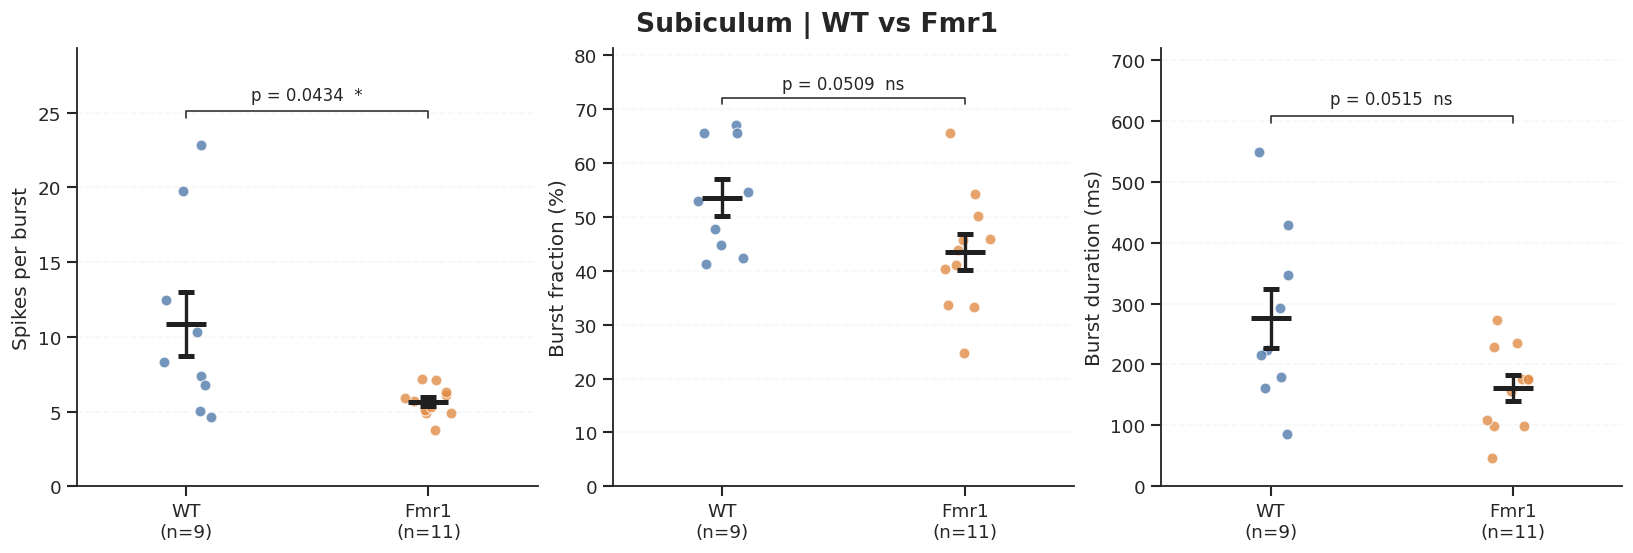


FIGURES SAVED
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_comparison_results/WT_vs_Fmr1_SUB_burst_metrics.png
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/WT_Fmr1_comparison_results/WT_vs_Fmr1_SUB_burst_metrics.pdf

FINAL FOLDER CONTENTS
WT_vs_Fmr1_APN_Welch.csv
WT_vs_Fmr1_CA1_Welch.csv
WT_vs_Fmr1_CA3_Welch.csv
WT_vs_Fmr1_CP_Welch.csv
WT_vs_Fmr1_DG_Welch.csv
WT_vs_Fmr1_MOs_Welch.csv
WT_vs_Fmr1_MRN_Welch.csv
WT_vs_Fmr1_SUB_Welch.csv
WT_vs_Fmr1_SUB_burst_metrics.pdf
WT_vs_Fmr1_SUB_burst_metrics.png
WT_vs_Fmr1_VISp_Welch.csv


In [46]:

# ============================================================
# WT vs FMR1 — ORGANIZE RESULTS AND PLOT SUBICULUM
#
# - Keep WT_Fmr1_comparison_results as the final directory
# - Remove the obsolete WT_vs_Fmr1 directory
# - Plot individual mouse observations
# - Mean +/- SEM
# - Two-sided Welch's t-test (unadjusted p-values)
# - Save publication-ready PNG and PDF
# ============================================================

import shutil

RESULTS_ROOT = ROOT / "04_results"

OLD_DIR = RESULTS_ROOT / "WT_vs_Fmr1"
RESULTS_DIR = RESULTS_ROOT / "WT_Fmr1_comparison_results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REGIONS = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

# ------------------------------------------------------------
# 1. CONSOLIDATE AND REMOVE OLD DIRECTORY
# ------------------------------------------------------------

for region in REGIONS:
    filename = f"WT_vs_Fmr1_{region}_Welch.csv"
    source = OLD_DIR / filename
    destination = RESULTS_DIR / filename

    if not destination.exists() and source.exists():
        shutil.copy2(source, destination)

missing = [
    region for region in REGIONS
    if not (
        RESULTS_DIR / f"WT_vs_Fmr1_{region}_Welch.csv"
    ).exists()
]

if missing:
    raise RuntimeError(
        f"Missing regional tables: {missing}. "
        "The old directory was not deleted."
    )

if OLD_DIR.exists():
    shutil.rmtree(OLD_DIR)
    print("Deleted obsolete folder:", OLD_DIR.name)

print("Final results directory:", RESULTS_DIR)
print("Regional tables verified:", len(REGIONS))


# ------------------------------------------------------------
# 2. LOAD MOUSE-LEVEL OBSERVATIONS
# ------------------------------------------------------------

mouse_data = pd.read_csv(
    RESULTS_ROOT / "WT_Fmr1_mouse_level.csv"
)

sub = mouse_data.loc[
    mouse_data["analysis_region"] == "SUB"
].copy()

METRICS = [
    ("spikes_per_burst", "Spikes per burst"),
    ("burst_fraction_pct", "Burst fraction (%)"),
    ("burst_duration_ms", "Burst duration (ms)")
]

# ------------------------------------------------------------
# 3. PLOT STYLE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

COLORS = {
    "WT": "#4C78A8",
    "Fmr1": "#E08B43"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 4.5),
    constrained_layout=True
)

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 4. THREE SUBICULUM METRICS
# ------------------------------------------------------------

for ax, (metric, ylabel) in zip(axes, METRICS):

    groups = []

    for i, genotype in enumerate(["WT", "Fmr1"]):

        values = sub.loc[
            sub["genotype"] == genotype,
            metric
        ].dropna().to_numpy(dtype=float)

        groups.append(values)

        jitter = rng.uniform(
            -0.11, 0.11, size=len(values)
        )

        # Individual mice.
        ax.scatter(
            np.full(len(values), i) + jitter,
            values,
            s=42,
            alpha=0.78,
            color=COLORS[genotype],
            edgecolor="white",
            linewidth=0.65,
            zorder=3
        )

        mean = np.mean(values)
        sem = (
            np.std(values, ddof=1) /
            np.sqrt(len(values))
        )

        # Group mean and SEM.
        ax.errorbar(
            i,
            mean,
            yerr=sem,
            fmt="_",
            markersize=24,
            markeredgewidth=3,
            elinewidth=2,
            capsize=5,
            color="#202020",
            zorder=5
        )

    # Independent Welch's t-test.
    test = ttest_ind(
        groups[0],
        groups[1],
        equal_var=False
    )

    p = float(test.pvalue)

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        f"WT\n(n={len(groups[0])})",
        f"Fmr1\n(n={len(groups[1])})"
    ])

    ax.set_xlim(-0.45, 1.45)
    ax.set_ylabel(ylabel)

    # Place p-value above the data.
    upper = max(
        np.max(groups[0]),
        np.max(groups[1])
    )

    lower = min(
        np.min(groups[0]),
        np.min(groups[1])
    )

    spread = max(upper - lower, 0.01)

    bracket_y = upper + spread * 0.12

    ax.plot(
        [0, 0, 1, 1],
        [
            bracket_y - spread * 0.025,
            bracket_y,
            bracket_y,
            bracket_y - spread * 0.025
        ],
        color="#333333",
        linewidth=1
    )

    significance = "*" if p < 0.05 else "ns"

    ax.text(
        0.5,
        bracket_y + spread * 0.025,
        f"p = {p:.4f}  {significance}",
        ha="center",
        va="bottom",
        fontsize=10
    )

    ax.set_ylim(
        min(0, lower - spread * 0.08),
        bracket_y + spread * 0.22
    )

    ax.grid(
        axis="y",
        alpha=0.15,
        linestyle="--"
    )

fig.suptitle(
    "Subiculum | WT vs Fmr1",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# 5. SAVE FIGURES
# ------------------------------------------------------------

png_path = RESULTS_DIR / "WT_vs_Fmr1_SUB_burst_metrics.png"
pdf_path = RESULTS_DIR / "WT_vs_Fmr1_SUB_burst_metrics.pdf"

fig.savefig(
    png_path,
    dpi=350,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("\nFIGURES SAVED")
print(png_path)
print(pdf_path)

print("\nFINAL FOLDER CONTENTS")
for file in sorted(RESULTS_DIR.iterdir()):
    print(file.name)


In [ ]:

# ============================================================
# CNTNAP2 — COMPLETE NEUROPIXELS ANALYSIS
# Same methodology as WT and Fmr1
#
# 16 mice / 85 insertions
# logisi_core_v1
# 24 Allen labels / 9 primary regions
# Saves each insertion immediately
# Resumable after interruption
#
# No WT or Fmr1 files are modified.
# ============================================================

GENOTYPE = "Cntnap2"
VERSION = "logisi_core_v1"

CNT_DIR = ROOT / "03_processed_data" / GENOTYPE
CNT_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = CNT_DIR / "processing_log.csv"

REGIONS = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

METRICS = [
    "fr_hz",
    "mean_isi_ms",
    "cv_isi",
    "cv2",
    "burst_rate_min",
    "burst_fraction_pct",
    "burst_duration_ms",
    "spikes_per_burst",
    "intraburst_hz",
    "interburst_interval_s"
]

REGION_MAP = dict(
    zip(atlas["allen_acronym"], atlas["analysis_region"])
)

VALID_REGIONS = set(atlas["allen_acronym"])

COLUMNS = [
    "subject", "genotype", "eid", "pid", "probe",
    "cluster_id", "original_region", "region",
    "duration_s", "n_spikes", "fr_hz",
    "mean_isi_ms", "cv_isi", "cv2",
    "logisi_threshold_ms", "burst_rate_min",
    "burst_fraction_pct", "burst_duration_ms",
    "spikes_per_burst", "intraburst_hz",
    "interburst_interval_s"
]


def save_atomic(data, path):
    """Replace a CSV only after writing its complete content."""
    tmp = path.with_name(path.name + ".tmp")
    try:
        data.to_csv(tmp, index=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


# ============================================================
# 1. RESTORE CNTNAP2 INVENTORY
# ============================================================

behavior_path = (
    ROOT.parent / "Behaviour" / "behavior_list_CSP.xlsx"
)

if not behavior_path.exists():
    raise FileNotFoundError(
        f"Behavior file not found: {behavior_path}"
    )

behavior = pd.read_excel(
    behavior_path,
    header=None
)

subjects = set(
    behavior.iloc[:, 0]
    .dropna()
    .astype(str)
    .str.strip()
)

print("Reference subjects:", len(subjects))

insertions = one.alyx.rest(
    "insertions",
    "list",
    django="session__projects__name,angelaki_mouseASD"
)

sessions = one.alyx.rest(
    "sessions",
    "list",
    django="projects__name,angelaki_mouseASD"
)


def get_uuid(value):
    if isinstance(value, dict):
        value = value.get("id", "")
    return str(value).rstrip("/").split("/")[-1]


session_lookup = {
    get_uuid(s["id"]): s
    for s in sessions
}

records = []

for ins in insertions:

    eid = get_uuid(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")

    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject).strip()

    if subject not in subjects:
        continue

    records.append({
        "pid": get_uuid(ins["id"]),
        "eid": eid,
        "subject": subject,
        "probe": ins.get("name"),
        "genotype": GENOTYPE
    })

inventory_cnt = (
    pd.DataFrame(
        records,
        columns=[
            "pid", "eid", "subject",
            "probe", "genotype"
        ]
    )
    .drop_duplicates("pid")
    .reset_index(drop=True)
)

print("\nCNTNAP2 INVENTORY")
print("Mice:", inventory_cnt.subject.nunique())
print("Insertions:", len(inventory_cnt))

assert inventory_cnt.subject.nunique() == 16, (
    "Incorrect cohort mapping: expected 16 mice."
)

assert len(inventory_cnt) == 85, (
    "Incorrect cohort mapping: expected 85 insertions."
)

# Ensure no probe insertion belongs to an already processed group.
other_pids = set()

for other_group in ["WT", "Fmr1"]:
    other_log = (
        ROOT / "03_processed_data" /
        other_group / "processing_log.csv"
    )

    if other_log.exists():
        other_pids.update(
            pd.read_csv(other_log)["pid"].astype(str)
        )

assert not (
    set(inventory_cnt["pid"]) & other_pids
), "Cohort overlap detected."

print("Cohort validated.")


# ============================================================
# 2. LOGISI-CORE THRESHOLD
# Identical algorithm to final WT and Fmr1
# ============================================================

def cnt_logisi_threshold(times, cutoff_ms=100.0):

    isi_ms = np.diff(times) * 1000

    isi_ms = isi_ms[
        np.isfinite(isi_ms) & (isi_ms > 0)
    ]

    if len(isi_ms) < 4:
        return np.nan

    included = isi_ms[isi_ms >= 1]

    if len(included) < 4:
        return np.nan

    max_power = max(
        1, int(np.ceil(np.log10(isi_ms.max())))
    )

    n_edges = max(11, 10 * max_power)

    edges = np.logspace(
        0, max_power, n_edges
    )

    counts, edges = np.histogram(
        included, bins=edges
    )

    if counts.sum() == 0:
        return np.nan

    density = counts.astype(float) / counts.sum()

    smooth = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        it=3,
        return_sorted=False
    )

    peaks = []

    for j in range(2, len(smooth) - 2):

        local = smooth[j - 2:j + 3]

        if (
            smooth[j] > local[1]
            and smooth[j] > local[3]
            and smooth[j] >= local[0]
            and smooth[j] >= local[4]
        ):
            if not peaks or j - peaks[-1] >= 2:
                peaks.append(j)

    peaks = np.asarray(peaks, dtype=int)

    if len(peaks) == 0:
        return np.nan

    peak_ms = edges[peaks]
    intraburst = peaks[peak_ms < cutoff_ms]

    if len(intraburst) == 0:
        return np.nan

    first = intraburst[
        np.argmax(smooth[intraburst])
    ]

    later = peaks[peaks > first]

    if len(later) == 0:
        return float(cutoff_ms)

    for second in later:

        valley = first + np.argmin(
            smooth[first:second + 1]
        )

        denominator = np.sqrt(
            max(smooth[first], 0) *
            max(smooth[second], 0)
        )

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void >= 0.7:

            threshold_ms = float(edges[valley])

            if threshold_ms < cutoff_ms:
                return threshold_ms

            return float(cutoff_ms)

    return float(cutoff_ms)


# ============================================================
# 3. NEURON ELECTROPHYSIOLOGY
# ============================================================

def cnt_neuron_metrics(times, duration):

    times = np.sort(np.asarray(times, dtype=float))

    n_spikes = len(times)
    isi = np.diff(times)
    positive = isi[isi > 0]

    result = {
        "n_spikes": n_spikes,
        "fr_hz": n_spikes / duration,
        "mean_isi_ms": (
            np.mean(positive) * 1000
            if len(positive) else np.nan
        ),
        "cv_isi": (
            np.std(positive) / np.mean(positive)
            if len(positive) >= 3 else np.nan
        ),
        "cv2": (
            np.mean(
                2 * np.abs(np.diff(positive)) /
                (positive[:-1] + positive[1:])
            )
            if len(positive) >= 3 else np.nan
        ),
        "logisi_threshold_ms": np.nan,
        "burst_rate_min": 0.0,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan
    }

    threshold_ms = cnt_logisi_threshold(times)

    result["logisi_threshold_ms"] = threshold_ms

    if not np.isfinite(threshold_ms):
        return result

    isi_short = (
        (isi > 0) &
        (isi <= threshold_ms / 1000)
    )

    starts = np.flatnonzero(
        isi_short & ~np.r_[False, isi_short[:-1]]
    )

    ends = np.flatnonzero(
        isi_short & ~np.r_[isi_short[1:], False]
    ) + 1

    valid = ends - starts + 1 >= 3

    starts = starts[valid]
    ends = ends[valid]

    n_bursts = len(starts)

    result["burst_rate_min"] = (
        n_bursts * 60 / duration
    )

    if n_bursts == 0:
        return result

    counts = ends - starts + 1
    durations = times[ends] - times[starts]

    result["burst_fraction_pct"] = (
        100 * counts.sum() / n_spikes
    )

    result["burst_duration_ms"] = (
        durations.mean() * 1000
    )

    result["spikes_per_burst"] = counts.mean()

    positive_durations = durations > 0

    if np.any(positive_durations):
        result["intraburst_hz"] = np.mean(
            (counts[positive_durations] - 1) /
            durations[positive_durations]
        )

    if n_bursts > 1:
        result["interburst_interval_s"] = np.mean(
            times[starts[1:]] - times[ends[:-1]]
        )

    return result


# ============================================================
# 4. PROCESS ONE INSERTION
# ============================================================

def process_cnt_insertion(rec):

    loader = SpikeSortingLoader(
        pid=str(rec.pid),
        one=one
    )

    spikes, clusters, channels = (
        loader.load_spike_sorting()
    )

    try:
        spike_times = np.asarray(spikes["times"])
        spike_clusters = np.asarray(spikes["clusters"])

        if len(spike_times) == 0:
            raise ValueError("Empty spike train")

        duration = float(
            spike_times.max() - spike_times.min()
        )

        if duration <= 0:
            raise ValueError("Invalid duration")

        clusters = loader.merge_clusters(
            spikes, clusters, channels
        )

        labels = np.asarray(clusters["label"])
        acronyms = np.asarray(clusters["acronym"])

        cluster_ids = np.asarray(
            clusters.get(
                "cluster_id",
                np.arange(len(labels))
            )
        )

        if not (
            len(labels) ==
            len(acronyms) ==
            len(cluster_ids)
        ):
            raise ValueError(
                "Cluster metadata mismatch"
            )

        order = np.argsort(
            spike_clusters,
            kind="stable"
        )

        sorted_ids = spike_clusters[order]
        sorted_times = spike_times[order]

        ids, starts, counts = np.unique(
            sorted_ids,
            return_index=True,
            return_counts=True
        )

        ranges = {
            int(cid): (int(start), int(count))
            for cid, start, count
            in zip(ids, starts, counts)
        }

        rows = []

        for i, cid in enumerate(cluster_ids):

            if labels[i] != 1:
                continue

            acronym = str(acronyms[i])

            if acronym not in VALID_REGIONS:
                continue

            bounds = ranges.get(int(cid))

            if bounds is None:
                continue

            start, count = bounds

            if count < 100:
                continue

            neuron_times = sorted_times[
                start:start + count
            ]

            metrics = cnt_neuron_metrics(
                neuron_times, duration
            )

            rows.append({
                "subject": rec.subject,
                "genotype": GENOTYPE,
                "eid": rec.eid,
                "pid": rec.pid,
                "probe": rec.probe,
                "cluster_id": int(cid),
                "original_region": acronym,
                "region": REGION_MAP[acronym],
                "duration_s": duration,
                **metrics
            })

        return pd.DataFrame(rows, columns=COLUMNS)

    finally:
        del spikes, clusters, channels
        gc.collect()


# ============================================================
# 5. PROCESS ALL INSERTIONS WITH RESUME SUPPORT
# ============================================================

if LOG_PATH.exists():
    log = pd.read_csv(LOG_PATH)
else:
    log = pd.DataFrame(
        columns=[
            "pid", "status", "neurons",
            "error", "burst_version"
        ]
    )

for col in [
    "pid", "status", "neurons", "error", "burst_version"
]:
    if col not in log:
        log[col] = ""

log["pid"] = log["pid"].astype(str)

processed = 0
skipped = 0
failed = 0

print("\n" + "=" * 60)
print("CNTNAP2 ELECTROPHYSIOLOGY")
print("=" * 60)

for i, rec in enumerate(
    inventory_cnt.itertuples(index=False), 1
):

    pid = str(rec.pid)
    path = CNT_DIR / f"{pid}.csv"

    previous = log.loc[log["pid"] == pid]

    is_done = (
        not previous.empty
        and previous["status"].iloc[-1] == "completed"
        and previous["burst_version"].iloc[-1] == VERSION
        and path.exists()
    )

    if is_done:
        skipped += 1
        continue

    try:
        result = process_cnt_insertion(rec)

        if result.duplicated(
            ["pid", "cluster_id"]
        ).any():
            raise ValueError("Duplicate neuron")

        if len(result):
            fractions = result["burst_fraction_pct"]

            if (
                fractions.lt(0).any()
                or fractions.gt(100).any()
            ):
                raise ValueError(
                    "Invalid burst fraction"
                )

        save_atomic(result, path)

        status = "completed"
        error = ""
        n = len(result)
        processed += 1

        print(
            f"[{i:03d}/85] "
            f"{rec.subject} | {rec.probe} | "
            f"neurons={n} | OK"
        )

    except Exception as exc:

        status = "error"
        error = str(exc)[:300]
        n = 0
        failed += 1

        print(
            f"[{i:03d}/85] ERROR: {error}"
        )

    log = log.loc[log["pid"] != pid]

    log = pd.concat([
        log,
        pd.DataFrame([{
            "pid": pid,
            "status": status,
            "neurons": n,
            "error": error,
            "burst_version": VERSION
        }])
    ], ignore_index=True)

    save_atomic(log, LOG_PATH)

    gc.collect()


# ============================================================
# 6. VERIFY COMPLETION
# ============================================================

completed = set(
    log.loc[
        (log["status"] == "completed") &
        (log["burst_version"] == VERSION),
        "pid"
    ].astype(str)
)

expected = set(inventory_cnt["pid"].astype(str))

n_completed = len(completed & expected)

print("\n" + "=" * 60)
print("CNTNAP2 PROCESSING SUMMARY")
print("=" * 60)

print("Processed now:", processed)
print("Already completed:", skipped)
print("Failed:", failed)
print("Total completed:", n_completed, "/ 85")

if n_completed != 85:
    raise RuntimeError(
        "Processing incomplete. Saved insertions can "
        "be resumed by rerunning this cell."
    )


# ============================================================
# 7. COMBINE ALL NEURON-LEVEL RESULTS
# ============================================================

parts = []

for pid in inventory_cnt["pid"].astype(str):

    part = pd.read_csv(
        CNT_DIR / f"{pid}.csv"
    )

    if not part.empty:
        parts.append(part)

if not parts:
    raise RuntimeError("No eligible neurons found")

neurons = pd.concat(
    parts, ignore_index=True
)

assert neurons["subject"].nunique() == 16
assert neurons["genotype"].eq(GENOTYPE).all()

assert not neurons.duplicated(
    ["pid", "cluster_id"]
).any()

save_atomic(
    neurons,
    CNT_DIR / "Cntnap2_all_neurons.csv"
)


# ============================================================
# 8. SUMMARY OF 24 ORIGINAL ALLEN LABELS
# ============================================================

mouse_24 = neurons.groupby(
    ["original_region", "subject"],
    as_index=False
)[METRICS].mean()

summary_24 = mouse_24.groupby(
    "original_region"
)[METRICS].mean()

n_mice_24 = mouse_24.groupby(
    "original_region"
)["subject"].nunique()

n_neurons_24 = neurons.groupby(
    "original_region"
).size()

summary_24.insert(
    0, "n_mice", n_mice_24
)

summary_24.insert(
    1, "n_neurons", n_neurons_24
)

summary_24 = summary_24.reindex(
    atlas["allen_acronym"]
)

summary_24.index.name = "Anatomical region"

save_atomic(
    summary_24.reset_index(),
    CNT_DIR / "Cntnap2_region_summary.csv"
)


# ============================================================
# 9. SUMMARY OF NINE PRIMARY BRAIN REGIONS
# ============================================================

primary = neurons.loc[
    neurons["region"].isin(REGIONS)
].copy()

mouse_9 = primary.groupby(
    ["region", "subject"],
    as_index=False
)[METRICS].mean()

summary_9 = mouse_9.groupby(
    "region"
)[METRICS].mean()

summary_9.insert(
    0,
    "n_mice",
    mouse_9.groupby("region")[
        "subject"
    ].nunique()
)

summary_9.insert(
    1,
    "n_neurons",
    primary.groupby("region").size()
)

summary_9 = summary_9.reindex(REGIONS)
summary_9.index.name = "Anatomical region"

save_atomic(
    summary_9.reset_index(),
    CNT_DIR / "Cntnap2_9_region_summary.csv"
)


# ============================================================
# 10. FINAL REPORT
# ============================================================

print("\n" + "=" * 60)
print("CNTNAP2 ANALYSIS COMPLETED")
print("=" * 60)

print("Mice:", neurons["subject"].nunique())
print("Insertions:", n_completed)
print("Neurons:", len(neurons))
print("Original anatomical labels:", len(summary_24))
print("Primary regions:", len(summary_9))
print("Burst method:", VERSION)

print("\nCNTNAP2 — NINE-REGION SUMMARY")
display(summary_9.round(3))

print("\nCNTNAP2 — 24-REGION SUMMARY")
display(summary_24.round(3))

print("\nAll results saved to:")
print(CNT_DIR)


Reference subjects: 25

CNTNAP2 INVENTORY
Mice: 16
Insertions: 85
Cohort validated.

CNTNAP2 ELECTROPHYSIOLOGY
Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/average_template_25.nrrd Bytes: 32998960


100%|██████████| 31.470260620117188/31.470260620117188 [00:01<00:00, 15.77it/s]


Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/annotation_25.nrrd Bytes: 4035363


100%|██████████| 3.848422050476074/3.848422050476074 [00:00<00:00,  4.33it/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 113M/113M [00:03<00:00, 31.8MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 56.6M/56.6M [00:01<00:00, 48.6MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 113M/113M [00:01<00:00, 61.5MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 113M/113M [00:01<00:00, 71.7MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe00/pykilosort/clusters.ch

[001/85] CSP033 | probe00 | neurons=8 | OK


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe01/pykilosort/spikes.depths.npy: 100%|██████████| 80.2M/80.2M [00:03<00:00, 26.4MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe01/pykilosort/spikes.clusters.npy: 100%|██████████| 40.1M/40.1M [00:01<00:00, 35.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe01/pykilosort/spikes.amps.npy: 100%|██████████| 80.2M/80.2M [00:01<00:00, 69.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe01/pykilosort/spikes.times.npy: 100%|██████████| 80.2M/80.2M [00:01<00:00, 66.8MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP033/2022-02-11/001/alf/probe01/pykilosort/clusters.channels.npy: 100%|██████████| 2.53k/2.53k [00:00<00:00, 5.45kB/s]
(S3) /r

... (16 outputs left out)

[010/85] CSP031 | probe01 | neurons=16 | OK


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 79.3M/79.3M [00:03<00:00, 25.5MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 79.3M/79.3M [00:01<00:00, 62.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 39.6M/39.6M [00:01<00:00, 34.3MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 79.3M/79.3M [00:01<00:00, 63.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 3.73k/3.73k [00:00<00:00, 7.98kB/s]
(S3) /r

[011/85] CSP031 | probe00 | neurons=16 | OK


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/CSP031/2022-02-03/001/alf/probe01/pykilosort/spikes.amps.npy:   1%|          | 786k/89.1M [00:01<02:12, 668kB/s]